# Gel Point Detection in Evolving Fluids

**Wavelet-Based Time-Frequency Analysis of Evolving Fluids in a Microfluidic Rheometer**

Haemograph Pty Ltd industry project, Master of Data Science.

This notebook builds one pipeline that finds the moment a liquid turns into a gel. In blood
that moment is the clot point, and finding it quickly and reliably is the whole reason
Haemograph's microfluidic rheometer exists.

The notebook is organised in five parts.

**Part 1. Real chirp data.** We take a genuine chirp rheology recording from an ARES G2
rheometer and turn it into viscoelastic spectra. The sample in that file happens to stiffen
by four orders of magnitude while it is being measured, so it is a real evolving material
and a real test of the pipeline.

**Part 2. Synthetic gelation with a known answer.** We build a gelling material in software
where we choose the gel time ourselves, so we can measure exactly how accurate a detector is.

**Part 3. MAPS rheology and artificial neural networks.** We implement the weakly nonlinear
MAPS response of the soft glassy rheology model, then train neural networks to read the
material state straight out of it. The question being tested is whether the nonlinear signal
moves before the linear one, which would mean early warning of the gel point.

**Part 4. The blood model.** The thixotropic elasto-visco-plastic model from the Armstrong
paper, which describes how blood structure breaks down and rebuilds under shear.

**Part 5. Summary and next steps.**

### References

[1] M. Armstrong, M. Scully, M. Clark, T. Corrigan, and C. James, "A simple approach for
adding thixotropy to an elasto-visco-plastic rheological model to facilitate structural
interrogation of human blood," *J. Non-Newtonian Fluid Mech.*, vol. 290, p. 104503, 2021.

[2] K. R. Lennon, J. D. J. Rathinaraj, M. A. Gonzalez Cadena, A. Santra, G. H. McKinley, and
J. W. Swan, "Anticipating gelation and vitrification with medium amplitude parallel
superposition (MAPS) rheology and artificial neural networks," *Rheol. Acta*, vol. 62,
pp. 535-556, 2023.

[3] B. Keshavarz, D. Gomes Rodrigues, J.-B. Champenois, M. G. Frith, J. Ilavsky, M. Geri,
T. Divoux, G. H. McKinley, and A. Poulesquen, "Time-connectivity superposition and the
gel/glass duality of weak colloidal gels," *Proc. Natl. Acad. Sci. USA*, vol. 118, no. 15,
p. e2022339118, 2021.

[4] M. Das, D. C. Vadillo, A. Perego, and G. H. McKinley, "Influence of initial phase angle on
optimally windowed strain-controlled chirp rheometry," *J. Rheol.*, vol. 70, pp. 361-381, 2026.

[5] J. Song, N. Holten-Andersen, and G. H. McKinley, "Non-Maxwellian viscoelastic stress
relaxations in soft matter," *Soft Matter*, vol. 19, pp. 7885-7906, 2023.

[6] E. Zohravi, N. Moreno, K. Hawkins, D. Curtis, and M. Ellero, "Mesoscale modelling of
fibrin clots: the interplay between rheology and microstructure at the gel point,"
*Soft Matter*, vol. 21, pp. 1141-1151, 2025.

[7] K. R. Lennon, G. H. McKinley, and J. W. Swan, "A data-driven method for automated data
superposition with applications in soft matter science," *Data-Centric Eng.*, vol. 4, p. e13, 2023.

[8] J. Holder, M. Badiei, K. Hawkins, C. Wright, P. R. Williams, and D. J. Curtis, "Control of
collagen gel mechanical properties through manipulation of gelation conditions near the sol-gel
transition," *Soft Matter*, vol. 14, pp. 574-580, 2018.

[9] H. H. Winter and F. Chambon, "Analysis of linear viscoelasticity of a crosslinking polymer
at the gel point," *J. Rheol.*, vol. 30, no. 2, pp. 367-382, 1986.

[10] M. J. L. Mills et al., "Evaluation of optimally windowed chirp signals in industrial
rheological measurements: method development and data processing," *Rheol. Acta*, 2025.

[11] D. E. Ghetmiri, A. J. Venturi, M. J. Cohen, and A. A. Menezes, "Quick model-based
viscoelastic clot strength predictions from blood protein concentrations for cybermedical
coagulation control," *Nat. Commun.*, vol. 14, p. 8317, 2023.

[12] J. Wang, C. U. Choi, and S. Shin, "Rapid microfluidic-thromboelastography for evaluating
whole blood coagulation and fibrinolysis at elevated shear rates," *Sens. Actuators B Chem.*,
vol. 390, p. 133873, 2023.

## Cell 1: Checking the environment

Before anything else we check which packages are installed and which are missing. Every
package listed here is used somewhere later in the notebook, so if something is reported as
missing the install command is printed right next to it.

Nothing here changes any data. It only reports what is available.

In [1]:
import importlib
import sys


def check_single_package(import_name, install_name, purpose):
    """
    Checking whether one package can be imported, and reporting its version.

    Returning True when the package is available and False when it is not, so the
    summary at the bottom can list exactly what still needs installing.
    """
    try:
        module_object = importlib.import_module(import_name)
        version_string = getattr(module_object, "__version__", "version unknown")
        print("  [ok]      " + import_name.ljust(16) + version_string.ljust(14) + purpose)
        return True
    except ImportError:
        print("  [missing] " + import_name.ljust(16) + "".ljust(14) + purpose)
        print("            install with: pip install " + install_name)
        return False


print("Python version")
print("  " + sys.version.replace("\n", " "))
print()

print("Package check")

packages_to_check = [
    ("numpy", "numpy", "numerical arrays, the backbone of everything here"),
    ("pandas", "pandas", "reading the rheometer spreadsheets"),
    ("scipy", "scipy", "signal processing, quadrature and the ODE solver"),
    ("matplotlib", "matplotlib", "all of the plots"),
    ("sklearn", "scikit-learn", "the neural networks used in Part 3"),
    ("pywt", "PyWavelets", "the continuous and discrete wavelet transforms"),
    ("openpyxl", "openpyxl", "the Excel reader pandas calls underneath"),
]

missing_package_names = []
for import_name, install_name, purpose in packages_to_check:
    package_is_available = check_single_package(import_name, install_name, purpose)
    if not package_is_available:
        missing_package_names.append(install_name)

print()
if len(missing_package_names) == 0:
    print("All required packages are present. The notebook can be run top to bottom.")
else:
    print("Missing packages: " + ", ".join(missing_package_names))
    print("Install them and then restart the kernel before continuing.")

Python version
  3.12.3 (main, Mar  3 2026, 12:15:18) [GCC 13.3.0]

Package check
  [ok]      numpy           2.4.4         numerical arrays, the backbone of everything here


  [ok]      pandas          3.0.2         reading the rheometer spreadsheets
  [ok]      scipy           1.17.1        signal processing, quadrature and the ODE solver
  [ok]      matplotlib      3.10.8        all of the plots


  [ok]      sklearn         1.8.0         the neural networks used in Part 3
  [ok]      pywt            1.8.0         the continuous and discrete wavelet transforms
  [ok]      openpyxl        3.1.5         the Excel reader pandas calls underneath

All required packages are present. The notebook can be run top to bottom.


## Cell 2: Configuration and the light plotting theme

This cell holds every setting that the rest of the notebook reads, so there is only one
place to edit when a path or a parameter changes.

It also sets a light plotting theme. Every figure in this notebook uses a white background
with dark text, which stays readable when printed or dropped into a report.

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

CHIRP_DATA_FILE = "DataZ.xlsx"

candidate_directories = [".", "./data", "../data", "/mnt/user-data/uploads"]

DATA_DIRECTORY = "."
for candidate_directory in candidate_directories:
    candidate_path = os.path.join(candidate_directory, CHIRP_DATA_FILE)
    if os.path.isfile(candidate_path):
        DATA_DIRECTORY = candidate_directory
        break

CHIRP_SAMPLING_FREQUENCY_HZ = 500.0

SPECTRUM_ENERGY_THRESHOLD = 0.05

SYNTHETIC_GEL_TIME_SECONDS = 500.0
SYNTHETIC_CRITICAL_EXPONENT = 0.60
SYNTHETIC_GEL_STIFFNESS = 50.0

MAPS_TONE_SET = (1.0, 4.0, 16.0)

ANN_TRAINING_SAMPLE_COUNT = 4000
ANN_RANDOM_SEED = 20260903

COLOUR_PRIMARY = "#1F4E79"
COLOUR_SECONDARY = "#C0504D"
COLOUR_ACCENT = "#7F9A3C"
COLOUR_NEUTRAL = "#8C8C8C"
COLOUR_HIGHLIGHT = "#E08A1E"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.labelcolor": "#222222",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.color": "#DDDDDD",
    "grid.linewidth": 0.7,
    "text.color": "#222222",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
    "legend.frameon": True,
    "legend.facecolor": "white",
    "legend.edgecolor": "#CCCCCC",
    "figure.dpi": 110,
})

print("Configuration loaded")
print("  data directory              " + DATA_DIRECTORY)
print("  chirp file                  " + CHIRP_DATA_FILE)
print("  chirp sampling frequency    " + str(CHIRP_SAMPLING_FREQUENCY_HZ) + " Hz")
print("  synthetic gel time          " + str(SYNTHETIC_GEL_TIME_SECONDS) + " s")
print("  synthetic critical exponent " + str(SYNTHETIC_CRITICAL_EXPONENT))
print("  MAPS tone set               " + str(MAPS_TONE_SET))
print("  ANN training samples        " + str(ANN_TRAINING_SAMPLE_COUNT))
print()
print("Light plotting theme applied to all figures.")

Configuration loaded
  data directory              .
  chirp file                  DataZ.xlsx
  chirp sampling frequency    500.0 Hz
  synthetic gel time          500.0 s
  synthetic critical exponent 0.6
  MAPS tone set               (1.0, 4.0, 16.0)
  ANN training samples        4000

Light plotting theme applied to all figures.


# Part 1: Real chirp data from an evolving material

## Cell 3: Loading the chirp dataset and splitting it into pulses

A chirp is a single sweep that runs through many frequencies one after another, from slow to
fast. Instead of measuring one frequency at a time, which is slow, a chirp measures the whole
frequency range in one short burst. That speed matters for a material that is changing while
you measure it, which is exactly the situation with clotting blood.

This file contains repeated chirp pulses fired at the same sample over about thirteen
minutes. Each pulse is stored as its own step, so we split the file by step number and
summarise what is in each one.

In [3]:
chirp_file_path = os.path.join(DATA_DIRECTORY, CHIRP_DATA_FILE)

print("Reading " + chirp_file_path)
chirp_dataframe = pd.read_excel(chirp_file_path, sheet_name="Sheet1")

print("Rows read: " + str(len(chirp_dataframe)))
print("Columns read: " + str(len(chirp_dataframe.columns)))
print()

chirp_pulse_list = []

unique_step_numbers = sorted(chirp_dataframe["Step_number"].unique())

for step_number in unique_step_numbers:

    single_step_dataframe = chirp_dataframe[chirp_dataframe["Step_number"] == step_number]

    run_time_values = single_step_dataframe["Run time [s]"].values
    strain_percent_values = single_step_dataframe["Strain (step) [%]"].values
    stress_pascal_values = single_step_dataframe["Stress (step) [Pa]"].values

    pulse_start_time = float(np.min(run_time_values))
    pulse_end_time = float(np.max(run_time_values))
    pulse_midpoint_time = 0.5 * (pulse_start_time + pulse_end_time)

    strain_amplitude_percent = float(np.max(np.abs(strain_percent_values)))
    stress_amplitude_pascal = float(np.max(np.abs(stress_pascal_values)))

    single_pulse_record = {
        "step_number": int(step_number),
        "start_time_seconds": pulse_start_time,
        "end_time_seconds": pulse_end_time,
        "midpoint_time_seconds": pulse_midpoint_time,
        "duration_seconds": pulse_end_time - pulse_start_time,
        "sample_count": len(run_time_values),
        "strain_amplitude_percent": strain_amplitude_percent,
        "stress_amplitude_pascal": stress_amplitude_pascal,
        "run_time_values": run_time_values,
        "strain_percent_values": strain_percent_values,
        "stress_percent_values": stress_pascal_values,
    }

    chirp_pulse_list.append(single_pulse_record)

print("Number of chirp pulses found: " + str(len(chirp_pulse_list)))
print()

print("step   start(s)   dur(s)   samples   strain amp(%)   stress amp(Pa)")
for single_pulse_record in chirp_pulse_list:
    print(
        str(single_pulse_record["step_number"]).rjust(4)
        + ("%10.1f" % single_pulse_record["start_time_seconds"])
        + ("%9.2f" % single_pulse_record["duration_seconds"])
        + ("%10d" % single_pulse_record["sample_count"])
        + ("%16.3f" % single_pulse_record["strain_amplitude_percent"])
        + ("%17.1f" % single_pulse_record["stress_amplitude_pascal"])
    )

print()
print("Notice that the strain amplitude is stepped down twice during the run while the")
print("stress amplitude keeps climbing. That is the operator protecting the instrument as")
print("the sample gets stiffer, and it is the first clue that this material is evolving.")

Reading ./DataZ.xlsx


Rows read: 120000
Columns read: 34

Number of chirp pulses found: 24

step   start(s)   dur(s)   samples   strain amp(%)   stress amp(Pa)
   1      14.9    10.00      5000          19.988             15.4
   2      46.6    10.00      5000          19.987             18.3
   3      78.3    10.00      5000          19.987             18.7
   4     109.9    10.00      5000          19.985             19.5
   5     141.5    10.00      5000          19.986             17.1
   6     173.1    10.00      5000          19.987             29.9
   7     204.7    10.00      5000          19.989             95.9
   8     238.3    10.00      5000           4.997             83.7
   9     269.9    10.00      5000           4.997            177.9
  10     301.5    10.00      5000           4.998            344.7
  11     346.3    10.00      5000           1.000            181.3
  12     377.9    10.00      5000           1.000            268.5
  13     409.5    10.00      5000           1.000         

## Cell 4: Looking at one raw chirp pulse

Before doing any maths on the signal it is worth simply looking at it. This cell plots the
strain the instrument applied and the stress the sample gave back, for a single pulse.

You should be able to see the oscillation start slow and get progressively faster across the
ten seconds. That speeding up is what makes it a chirp.

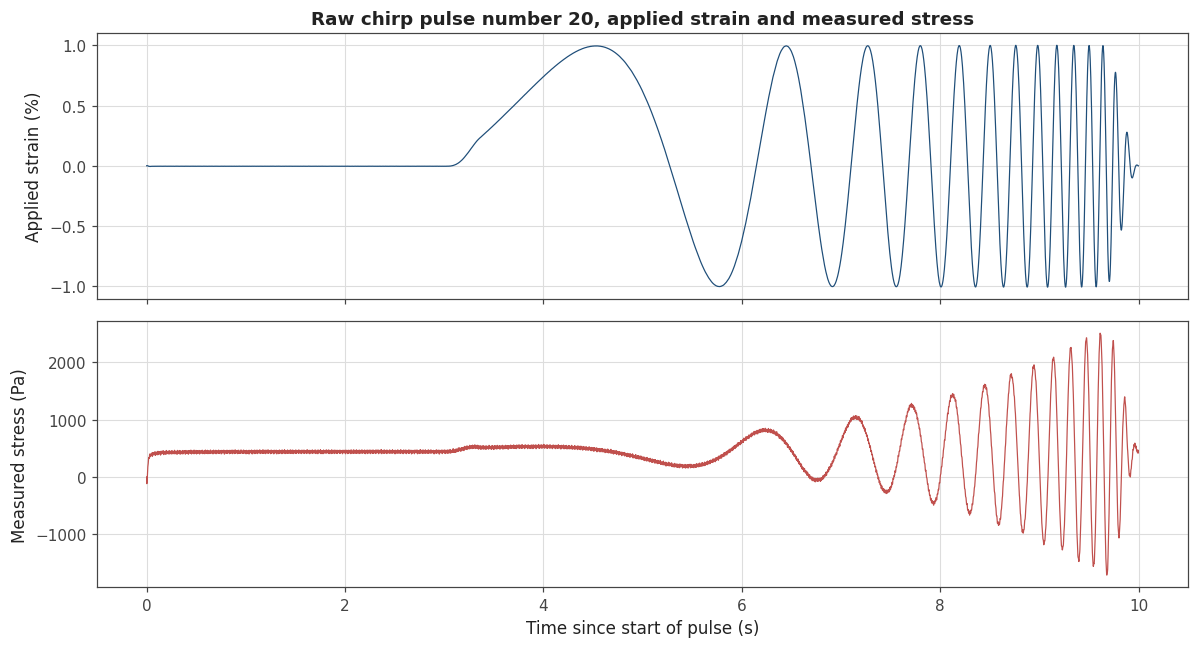

Pulse duration: 10.00 s
Samples in pulse: 5000
Sampling rate: 500.1 Hz


In [4]:
pulse_index_to_plot = 19

selected_pulse = chirp_pulse_list[pulse_index_to_plot]

local_time_values = selected_pulse["run_time_values"] - selected_pulse["start_time_seconds"]
local_strain_values = selected_pulse["strain_percent_values"]
local_stress_values = selected_pulse["stress_percent_values"]

figure_object, axis_array = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

axis_array[0].plot(local_time_values, local_strain_values,
                   color=COLOUR_PRIMARY, linewidth=0.8)
axis_array[0].set_ylabel("Applied strain (%)")
axis_array[0].set_title("Raw chirp pulse number "
                        + str(selected_pulse["step_number"])
                        + ", applied strain and measured stress")

axis_array[1].plot(local_time_values, local_stress_values,
                   color=COLOUR_SECONDARY, linewidth=0.8)
axis_array[1].set_ylabel("Measured stress (Pa)")
axis_array[1].set_xlabel("Time since start of pulse (s)")

plt.tight_layout()
plt.show()

print("Pulse duration: " + ("%.2f" % selected_pulse["duration_seconds"]) + " s")
print("Samples in pulse: " + str(selected_pulse["sample_count"]))
print("Sampling rate: "
      + ("%.1f" % (selected_pulse["sample_count"] / selected_pulse["duration_seconds"]))
      + " Hz")

## Cell 5: Seeing the chirp in time and frequency together

A chirp changes its frequency as it goes, so a single ordinary Fourier transform of the whole
pulse tells you which frequencies are present but not when each one arrived. To see both at
once we need a time-frequency method.

This cell compares two of them side by side on the same pulse:

- the **short-time Fourier transform**, which slides one fixed-length window along the signal
- the **continuous wavelet transform**, which automatically uses short windows for fast
  wiggles and long windows for slow ones

The bright diagonal ridge in each picture is the chirp sweeping upward in frequency. The
wavelet version follows that ridge more tightly at low frequency, which is the reason this
project is interested in wavelets in the first place.

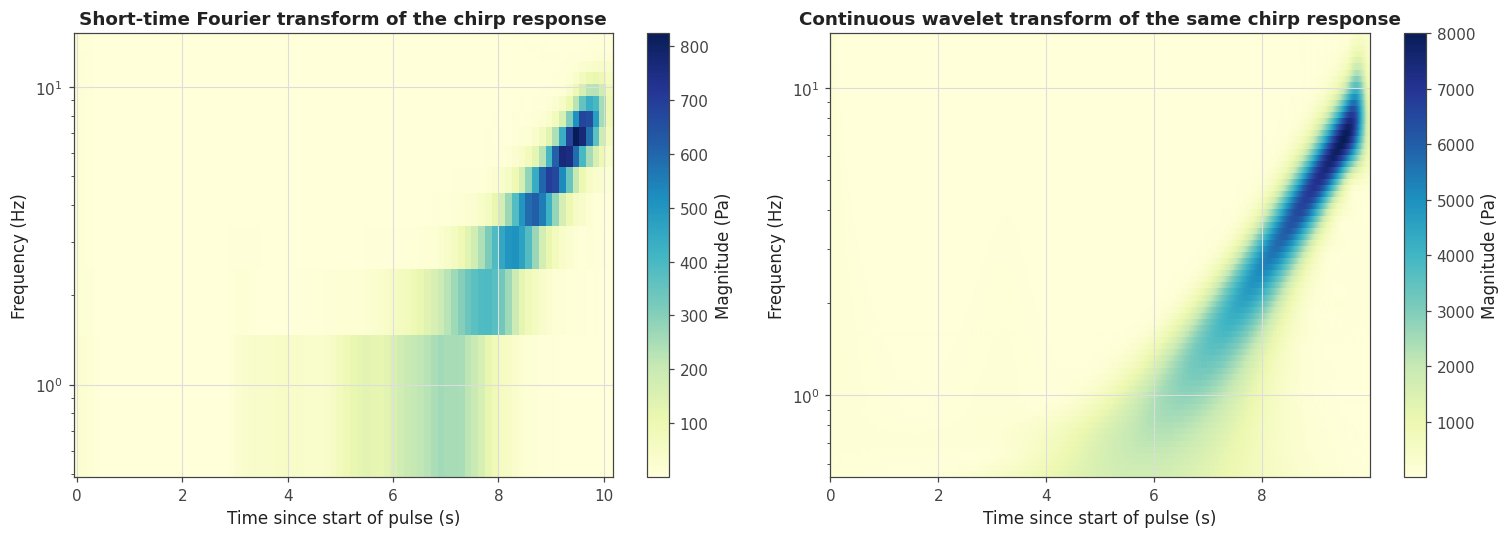

Both pictures show the same event, the chirp sweeping upward in frequency.
The wavelet version tracks the low-frequency start of the sweep more tightly,
because it lengthens its window automatically when the oscillation is slow.


In [5]:
import pywt
from scipy import signal as scipy_signal

signal_for_analysis = local_stress_values - np.mean(local_stress_values)
sampling_period_seconds = 1.0 / CHIRP_SAMPLING_FREQUENCY_HZ

stft_frequencies, stft_times, stft_values = scipy_signal.stft(
    signal_for_analysis,
    fs=CHIRP_SAMPLING_FREQUENCY_HZ,
    nperseg=512,
    noverlap=448,
    window="hann",
)
stft_magnitude = np.abs(stft_values)

wavelet_name = "cmor1.5-1.0"

wavelet_scales = np.geomspace(4.0, 900.0, 120)
wavelet_coefficients, wavelet_frequencies = pywt.cwt(
    signal_for_analysis, wavelet_scales, wavelet_name, sampling_period=sampling_period_seconds
)
wavelet_magnitude = np.abs(wavelet_coefficients)

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5))

stft_frequency_mask = (stft_frequencies > 0.02) & (stft_frequencies < 15.0)
mesh_left = axis_array[0].pcolormesh(
    stft_times,
    stft_frequencies[stft_frequency_mask],
    stft_magnitude[stft_frequency_mask, :],
    shading="auto",
    cmap="YlGnBu",
)
axis_array[0].set_yscale("log")
axis_array[0].set_xlabel("Time since start of pulse (s)")
axis_array[0].set_ylabel("Frequency (Hz)")
axis_array[0].set_title("Short-time Fourier transform of the chirp response")
figure_object.colorbar(mesh_left, ax=axis_array[0], label="Magnitude (Pa)")

wavelet_frequency_mask = (wavelet_frequencies > 0.02) & (wavelet_frequencies < 15.0)
mesh_right = axis_array[1].pcolormesh(
    local_time_values,
    wavelet_frequencies[wavelet_frequency_mask],
    wavelet_magnitude[wavelet_frequency_mask, :],
    shading="auto",
    cmap="YlGnBu",
)
axis_array[1].set_yscale("log")
axis_array[1].set_xlabel("Time since start of pulse (s)")
axis_array[1].set_ylabel("Frequency (Hz)")
axis_array[1].set_title("Continuous wavelet transform of the same chirp response")
figure_object.colorbar(mesh_right, ax=axis_array[1], label="Magnitude (Pa)")

plt.tight_layout()
plt.show()

print("Both pictures show the same event, the chirp sweeping upward in frequency.")
print("The wavelet version tracks the low-frequency start of the sweep more tightly,")
print("because it lengthens its window automatically when the oscillation is slow.")

## Cell 6: Turning one chirp into a viscoelastic spectrum

Now we convert a chirp pulse into the two numbers rheologists actually care about.

**Storage modulus G prime** measures the solid-like, springy part of the response.
**Loss modulus G double prime** measures the liquid-like, gooey part.

The ratio of the two is **tan delta**. When tan delta is large the material is mostly liquid.
When it is small the material is mostly solid. Where it passes through one, the two are equal.

We get both by taking the Fourier transform of the stress and dividing it by the Fourier
transform of the strain. The important safety step is the energy mask: we only trust
frequencies where the applied strain actually put energy into the sample. Everywhere else the
division is noise divided by noise, which produces meaningless and sometimes negative moduli.

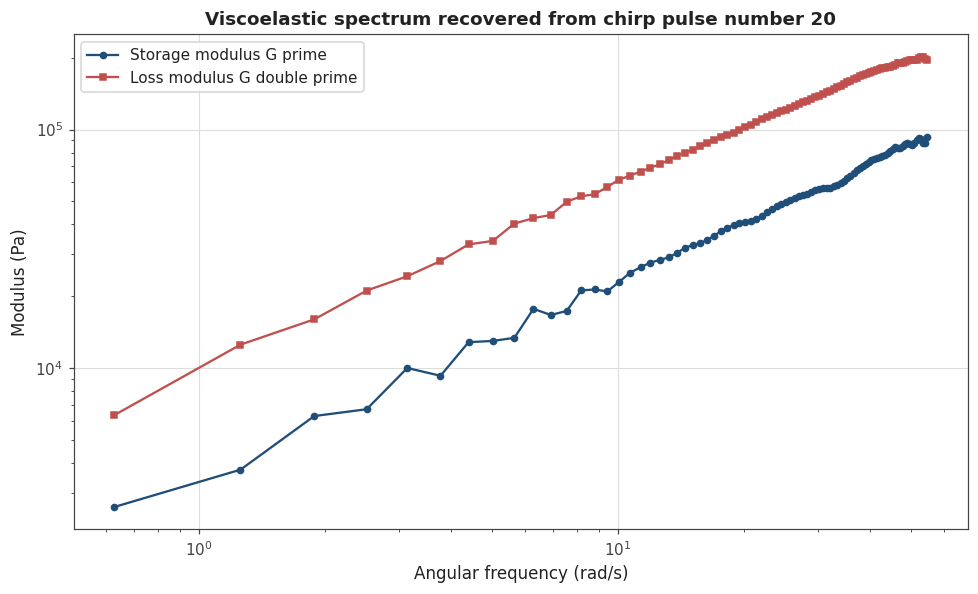

Usable frequency band: 0.63 to 54.66 rad/s
Number of usable frequency points: 87


In [6]:
from scipy.signal import get_window


def extract_complex_modulus_from_pulse(strain_percent_values, stress_pascal_values,
                                       sampling_frequency_hz, energy_threshold_fraction):
    """
    Converting one chirp pulse into a complex modulus spectrum.

    Taking the Fourier transform of both the applied strain and the measured stress, then
    dividing one by the other at every frequency. Keeping only the frequencies where the
    strain spectrum carries a meaningful share of the total energy, because outside that
    band the division is unreliable.

    Returning the angular frequency array in rad/s and the matching complex modulus in Pa.
    """
    strain_fraction_values = strain_percent_values / 100.0

    strain_centred = strain_fraction_values - np.mean(strain_fraction_values)
    stress_centred = stress_pascal_values - np.mean(stress_pascal_values)

    sample_count = len(strain_centred)
    taper_window = get_window(("tukey", 0.1), sample_count)

    strain_spectrum = np.fft.rfft(strain_centred * taper_window)
    stress_spectrum = np.fft.rfft(stress_centred * taper_window)

    frequency_hz_values = np.fft.rfftfreq(sample_count, 1.0 / sampling_frequency_hz)
    angular_frequency_values = 2.0 * np.pi * frequency_hz_values

    strain_magnitude = np.abs(strain_spectrum)
    largest_strain_magnitude = np.max(strain_magnitude)

    keep_mask = strain_magnitude > (energy_threshold_fraction * largest_strain_magnitude)
    keep_mask = keep_mask & (angular_frequency_values > 0.0)

    kept_angular_frequency = angular_frequency_values[keep_mask]
    kept_complex_modulus = stress_spectrum[keep_mask] / strain_spectrum[keep_mask]

    sort_order = np.argsort(kept_angular_frequency)

    return kept_angular_frequency[sort_order], kept_complex_modulus[sort_order]


example_angular_frequency, example_complex_modulus = extract_complex_modulus_from_pulse(
    selected_pulse["strain_percent_values"],
    selected_pulse["stress_percent_values"],
    CHIRP_SAMPLING_FREQUENCY_HZ,
    SPECTRUM_ENERGY_THRESHOLD,
)

example_storage_modulus = example_complex_modulus.real
example_loss_modulus = example_complex_modulus.imag

figure_object, axis_object = plt.subplots(figsize=(9, 5.5))

axis_object.loglog(example_angular_frequency, example_storage_modulus,
                   "o-", color=COLOUR_PRIMARY, markersize=4,
                   label="Storage modulus G prime")
axis_object.loglog(example_angular_frequency, example_loss_modulus,
                   "s-", color=COLOUR_SECONDARY, markersize=4,
                   label="Loss modulus G double prime")

axis_object.set_xlabel("Angular frequency (rad/s)")
axis_object.set_ylabel("Modulus (Pa)")
axis_object.set_title("Viscoelastic spectrum recovered from chirp pulse number "
                      + str(selected_pulse["step_number"]))
axis_object.legend()

plt.tight_layout()
plt.show()

print("Usable frequency band: "
      + ("%.2f" % example_angular_frequency.min()) + " to "
      + ("%.2f" % example_angular_frequency.max()) + " rad/s")
print("Number of usable frequency points: " + str(len(example_angular_frequency)))

## Cell 7: How the spectrum evolves across the whole run

Now we repeat the extraction for every pulse in the file and stack the results. Because each
pulse is a snapshot taken at a different moment, laying them out together shows how the
material changed while it was being measured.

The left panel shows the whole family of spectra. The right panel picks one frequency and
follows the two moduli through time.

Spectra extracted for 24 pulses.



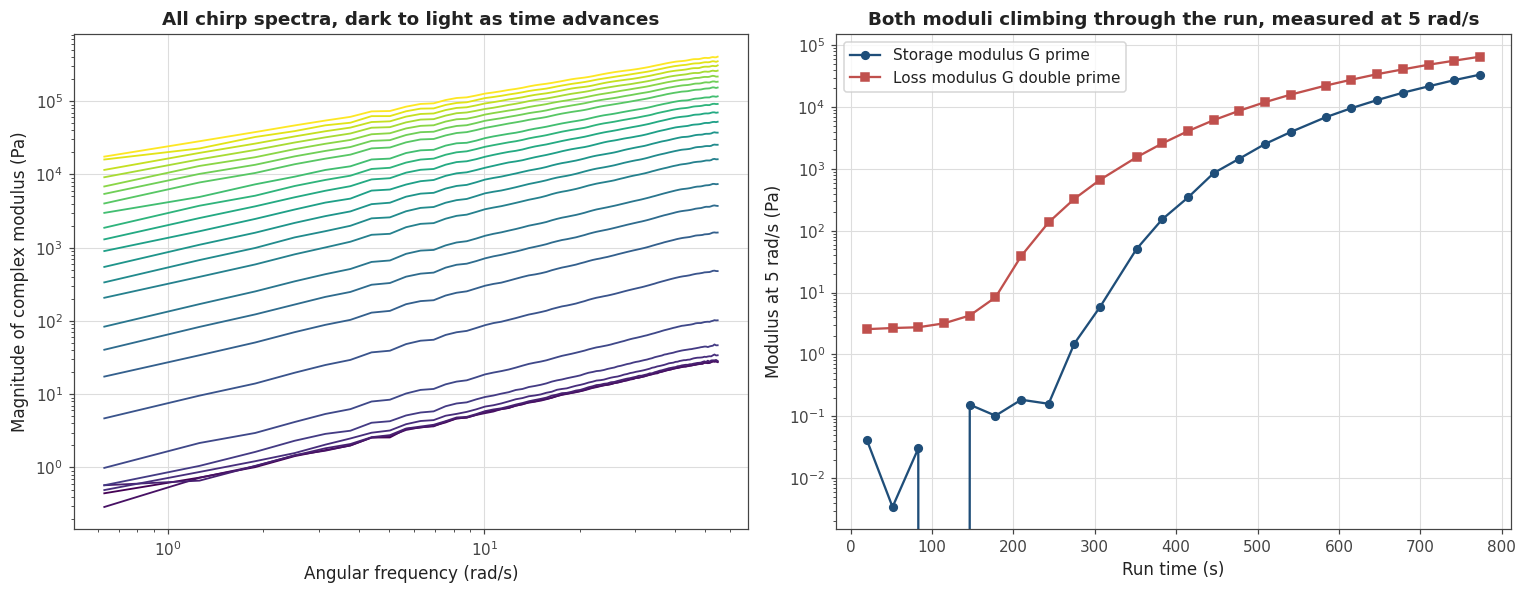

Storage modulus at 5 rad/s went from 0.0422 Pa to 3.35e+04 Pa.
That is a rise of roughly 793921 times over about 753 seconds.


In [7]:
spectrum_results_by_pulse = []

for single_pulse_record in chirp_pulse_list:

    pulse_angular_frequency, pulse_complex_modulus = extract_complex_modulus_from_pulse(
        single_pulse_record["strain_percent_values"],
        single_pulse_record["stress_percent_values"],
        CHIRP_SAMPLING_FREQUENCY_HZ,
        SPECTRUM_ENERGY_THRESHOLD,
    )

    single_spectrum_record = {
        "step_number": single_pulse_record["step_number"],
        "midpoint_time_seconds": single_pulse_record["midpoint_time_seconds"],
        "angular_frequency": pulse_angular_frequency,
        "complex_modulus": pulse_complex_modulus,
    }

    spectrum_results_by_pulse.append(single_spectrum_record)

print("Spectra extracted for " + str(len(spectrum_results_by_pulse)) + " pulses.")
print()


def interpolate_modulus_at_frequency(angular_frequency_array, complex_modulus_array,
                                     target_angular_frequency):
    """
    Reading the complex modulus off a spectrum at one chosen frequency.

    Interpolating the real and imaginary parts separately in log frequency, and returning
    a NaN when the requested frequency falls outside the measured band.
    """
    if target_angular_frequency < angular_frequency_array.min():
        return np.nan + 1j * np.nan
    if target_angular_frequency > angular_frequency_array.max():
        return np.nan + 1j * np.nan

    log_frequency_array = np.log(angular_frequency_array)
    log_target_frequency = np.log(target_angular_frequency)

    real_part = np.interp(log_target_frequency, log_frequency_array, complex_modulus_array.real)
    imaginary_part = np.interp(log_target_frequency, log_frequency_array,
                               complex_modulus_array.imag)

    return real_part + 1j * imaginary_part


tracking_angular_frequency = 5.0

tracking_time_list = []
tracking_storage_list = []
tracking_loss_list = []

for single_spectrum_record in spectrum_results_by_pulse:

    interpolated_modulus = interpolate_modulus_at_frequency(
        single_spectrum_record["angular_frequency"],
        single_spectrum_record["complex_modulus"],
        tracking_angular_frequency,
    )

    tracking_time_list.append(single_spectrum_record["midpoint_time_seconds"])
    tracking_storage_list.append(interpolated_modulus.real)
    tracking_loss_list.append(interpolated_modulus.imag)

tracking_time_array = np.array(tracking_time_list)
tracking_storage_array = np.array(tracking_storage_list)
tracking_loss_array = np.array(tracking_loss_list)

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5.5))

colour_map_object = plt.get_cmap("viridis")

for spectrum_index, single_spectrum_record in enumerate(spectrum_results_by_pulse):
    line_colour = colour_map_object(spectrum_index / max(1, len(spectrum_results_by_pulse) - 1))
    axis_array[0].loglog(
        single_spectrum_record["angular_frequency"],
        np.abs(single_spectrum_record["complex_modulus"]),
        "-", color=line_colour, linewidth=1.2,
    )

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Magnitude of complex modulus (Pa)")
axis_array[0].set_title("All chirp spectra, dark to light as time advances")

axis_array[1].semilogy(tracking_time_array, tracking_storage_array,
                       "o-", color=COLOUR_PRIMARY, markersize=5,
                       label="Storage modulus G prime")
axis_array[1].semilogy(tracking_time_array, tracking_loss_array,
                       "s-", color=COLOUR_SECONDARY, markersize=5,
                       label="Loss modulus G double prime")
axis_array[1].set_xlabel("Run time (s)")
axis_array[1].set_ylabel("Modulus at 5 rad/s (Pa)")
axis_array[1].set_title("Both moduli climbing through the run, measured at 5 rad/s")
axis_array[1].legend()

plt.tight_layout()
plt.show()

print("Storage modulus at 5 rad/s went from "
      + ("%.3g" % tracking_storage_array[0]) + " Pa to "
      + ("%.3g" % tracking_storage_array[-1]) + " Pa.")
print("That is a rise of roughly "
      + ("%.0f" % (tracking_storage_array[-1] / max(tracking_storage_array[0], 1e-9)))
      + " times over about "
      + ("%.0f" % (tracking_time_array[-1] - tracking_time_array[0])) + " seconds.")

## Cell 8: Looking for the gel point in the real data

There are two standard ways to call the gel point.

**The crossover.** The moment when G prime equals G double prime at one chosen frequency,
so tan delta passes through one. This is easy and it is what most clinical clot-time
instruments report, but the answer you get depends on which frequency you chose.

**The Winter and Chambon criterion.** At the true gel point tan delta becomes the same at
every frequency. So instead of watching one frequency, we watch how much the tan delta values
at different frequencies disagree with each other, and look for the moment that disagreement
is smallest. This is the rigorous definition and it does not depend on an arbitrary choice.

This cell applies both to the real chirp data.

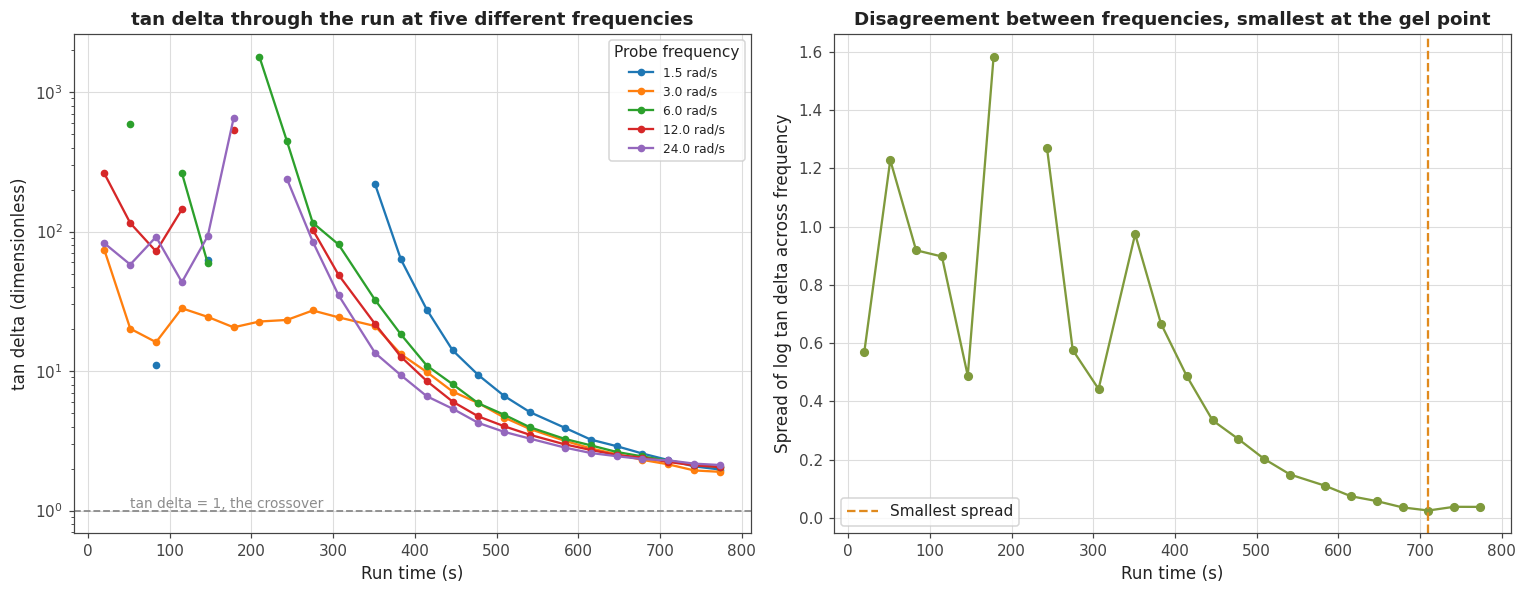

Winter and Chambon estimate from the smallest spread: 710.1 s

Reading this honestly:
  tan delta is still above one at every frequency at the end of the record, so this
  material has not finished crossing over inside the time we can see. The five curves
  are converging toward each other though, which is the Winter and Chambon signature
  starting to appear. The pipeline works, but this particular file stops too early to
  contain a confirmed gel point, and there is no independent reference gel time to
  score the estimate against.


In [8]:
probe_angular_frequencies = np.array([1.5, 3.0, 6.0, 12.0, 24.0])

tan_delta_matrix = np.full((len(spectrum_results_by_pulse), len(probe_angular_frequencies)),
                           np.nan)
spectrum_time_array = np.array([record["midpoint_time_seconds"]
                                for record in spectrum_results_by_pulse])

for spectrum_index, single_spectrum_record in enumerate(spectrum_results_by_pulse):

    for frequency_index in range(len(probe_angular_frequencies)):

        target_frequency = probe_angular_frequencies[frequency_index]

        interpolated_modulus = interpolate_modulus_at_frequency(
            single_spectrum_record["angular_frequency"],
            single_spectrum_record["complex_modulus"],
            target_frequency,
        )

        storage_part = interpolated_modulus.real
        loss_part = interpolated_modulus.imag

        if np.isfinite(storage_part) and np.isfinite(loss_part) and storage_part > 0.0:
            tan_delta_matrix[spectrum_index, frequency_index] = loss_part / storage_part

tan_delta_spread_array = np.full(len(spectrum_results_by_pulse), np.nan)

for spectrum_index in range(len(spectrum_results_by_pulse)):
    row_values = tan_delta_matrix[spectrum_index, :]
    finite_values = row_values[np.isfinite(row_values)]
    if len(finite_values) >= 3:
        tan_delta_spread_array[spectrum_index] = np.std(np.log(finite_values))

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5.5))

for frequency_index in range(len(probe_angular_frequencies)):
    axis_array[0].semilogy(
        spectrum_time_array,
        tan_delta_matrix[:, frequency_index],
        "o-", markersize=4,
        label=("%.1f rad/s" % probe_angular_frequencies[frequency_index]),
    )

axis_array[0].axhline(1.0, color=COLOUR_NEUTRAL, linestyle="--", linewidth=1.2)
axis_array[0].text(spectrum_time_array[1], 1.05, "tan delta = 1, the crossover",
                   color=COLOUR_NEUTRAL, fontsize=9)
axis_array[0].set_xlabel("Run time (s)")
axis_array[0].set_ylabel("tan delta (dimensionless)")
axis_array[0].set_title("tan delta through the run at five different frequencies")
axis_array[0].legend(title="Probe frequency", fontsize=8)

axis_array[1].plot(spectrum_time_array, tan_delta_spread_array,
                   "o-", color=COLOUR_ACCENT, markersize=5)
axis_array[1].set_xlabel("Run time (s)")
axis_array[1].set_ylabel("Spread of log tan delta across frequency")
axis_array[1].set_title("Disagreement between frequencies, smallest at the gel point")

finite_spread_mask = np.isfinite(tan_delta_spread_array)
if np.any(finite_spread_mask):
    smallest_spread_index = int(np.nanargmin(tan_delta_spread_array))
    axis_array[1].axvline(spectrum_time_array[smallest_spread_index],
                          color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.5,
                          label="Smallest spread")
    axis_array[1].legend()

plt.tight_layout()
plt.show()

print("Winter and Chambon estimate from the smallest spread: "
      + ("%.1f" % spectrum_time_array[smallest_spread_index]) + " s")
print()
print("Reading this honestly:")
print("  tan delta is still above one at every frequency at the end of the record, so this")
print("  material has not finished crossing over inside the time we can see. The five curves")
print("  are converging toward each other though, which is the Winter and Chambon signature")
print("  starting to appear. The pipeline works, but this particular file stops too early to")
print("  contain a confirmed gel point, and there is no independent reference gel time to")
print("  score the estimate against.")

# Part 2: A synthetic gelling material with a known answer

## Cell 9: Building a gelling material in software

The real file in Part 1 showed us the pipeline runs, but it cannot tell us how accurate the
pipeline is, because nobody knows the true gel time of that sample. To measure accuracy we
need a material where we choose the gel time ourselves.

We build one from the fractional viscoelastic models described in references [5] and [8].
The idea is simple.

**Before the gel point** the material is still a liquid. It is described by a fractional
Maxwell model with a longest relaxation time that grows as the network builds up, and that
relaxation time runs off to infinity right at the gel point.

**Exactly at the gel point** the model collapses to a single power law in frequency. Both
moduli then rise with the same slope, so tan delta is the same at every frequency, equal to
tan of n pi over two. That is the Winter and Chambon condition from reference [9].

**After the gel point** the material is a solid. A stiffness that grows from zero is added in
parallel with the power law, which is a fractional Kelvin-Voigt form.

Because we write the gel time into the model by hand, we know the correct answer exactly and
can measure how far any detector lands from it.

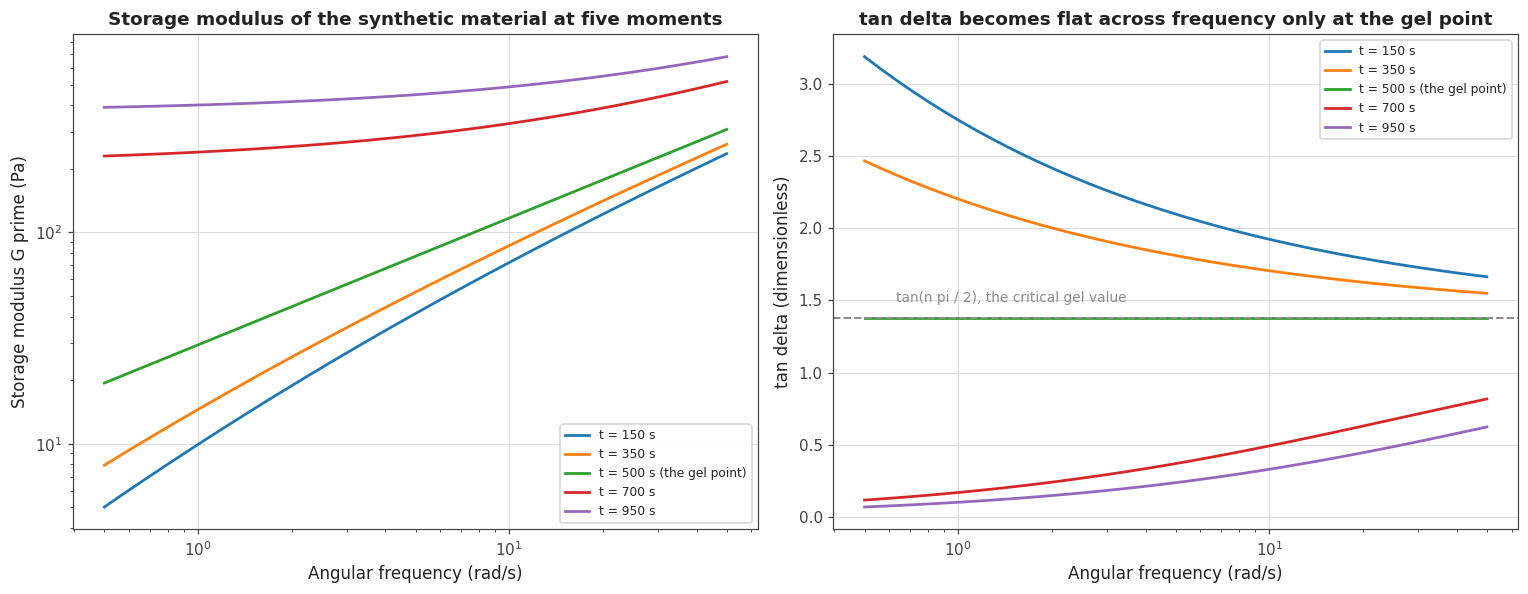

Critical exponent chosen: 0.6
Expected tan delta at the gel point: 1.3764
Gel time written into the model: 500.0 s


In [9]:
def complex_modulus_of_gelling_material(angular_frequency_array, elapsed_time_seconds,
                                        gel_time_seconds, critical_exponent, gel_stiffness,
                                        reference_time_seconds=1.0,
                                        divergence_exponent=1.5,
                                        plateau_scale_pascal=400.0,
                                        plateau_growth_exponent=0.7):
    """
    Computing the complex modulus of a synthetic gelling material at one moment in time.

    Using a fractional Maxwell form before the gel point, where the longest relaxation time
    diverges as the gel point is approached, and a fractional Kelvin-Voigt form after it,
    where an equilibrium stiffness grows away from zero. Both forms collapse to the same
    single power law exactly at the gel point, which is the critical gel state.

    Returning the complex modulus in Pa, one value per requested angular frequency.
    """
    imaginary_frequency = 1j * angular_frequency_array

    if elapsed_time_seconds < gel_time_seconds:

        distance_from_gel_point = 1.0 - (elapsed_time_seconds / gel_time_seconds)
        longest_relaxation_time = reference_time_seconds * (
            distance_from_gel_point ** (-divergence_exponent)
        )

        dimensionless_group = (imaginary_frequency * longest_relaxation_time) ** (
            1.0 - critical_exponent
        )

        critical_gel_part = gel_stiffness * (imaginary_frequency ** critical_exponent)
        complex_modulus = critical_gel_part * dimensionless_group / (1.0 + dimensionless_group)

    else:

        time_past_gel_point = (elapsed_time_seconds - gel_time_seconds) / gel_time_seconds
        equilibrium_modulus = plateau_scale_pascal * (
            time_past_gel_point ** plateau_growth_exponent
        )

        complex_modulus = equilibrium_modulus + gel_stiffness * (
            imaginary_frequency ** critical_exponent
        )

    return complex_modulus


demonstration_frequencies = np.logspace(np.log10(0.5), np.log10(50.0), 40)

demonstration_times = [150.0, 350.0, SYNTHETIC_GEL_TIME_SECONDS, 700.0, 950.0]

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5.5))

for demonstration_time in demonstration_times:

    modulus_at_this_time = complex_modulus_of_gelling_material(
        demonstration_frequencies, demonstration_time,
        SYNTHETIC_GEL_TIME_SECONDS, SYNTHETIC_CRITICAL_EXPONENT, SYNTHETIC_GEL_STIFFNESS,
    )

    time_label = ("t = %.0f s" % demonstration_time)
    if abs(demonstration_time - SYNTHETIC_GEL_TIME_SECONDS) < 1.0:
        time_label = time_label + " (the gel point)"

    axis_array[0].loglog(demonstration_frequencies, modulus_at_this_time.real,
                         "-", linewidth=1.8, label=time_label)
    axis_array[1].semilogx(demonstration_frequencies,
                           modulus_at_this_time.imag / modulus_at_this_time.real,
                           "-", linewidth=1.8, label=time_label)

expected_critical_tan_delta = np.tan(SYNTHETIC_CRITICAL_EXPONENT * np.pi / 2.0)
axis_array[1].axhline(expected_critical_tan_delta, color=COLOUR_NEUTRAL,
                      linestyle="--", linewidth=1.3)
axis_array[1].text(demonstration_frequencies[2], expected_critical_tan_delta * 1.08,
                   "tan(n pi / 2), the critical gel value",
                   color=COLOUR_NEUTRAL, fontsize=9)

axis_array[0].set_xlabel("Angular frequency (rad/s)")
axis_array[0].set_ylabel("Storage modulus G prime (Pa)")
axis_array[0].set_title("Storage modulus of the synthetic material at five moments")
axis_array[0].legend(fontsize=8)

axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("tan delta (dimensionless)")
axis_array[1].set_title("tan delta becomes flat across frequency only at the gel point")
axis_array[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Critical exponent chosen: " + str(SYNTHETIC_CRITICAL_EXPONENT))
print("Expected tan delta at the gel point: " + ("%.4f" % expected_critical_tan_delta))
print("Gel time written into the model: " + str(SYNTHETIC_GEL_TIME_SECONDS) + " s")

## Cell 10: Generating a synthetic chirp-probed gelation experiment

Now we simulate the experiment we would actually run on the rheometer. We fire a chirp at the
synthetic material every so often, exactly as the real file in Part 1 did, and we add
measurement noise so the data looks like something an instrument would really produce.

The result is a stack of noisy spectral snapshots with a gel time we know exactly.

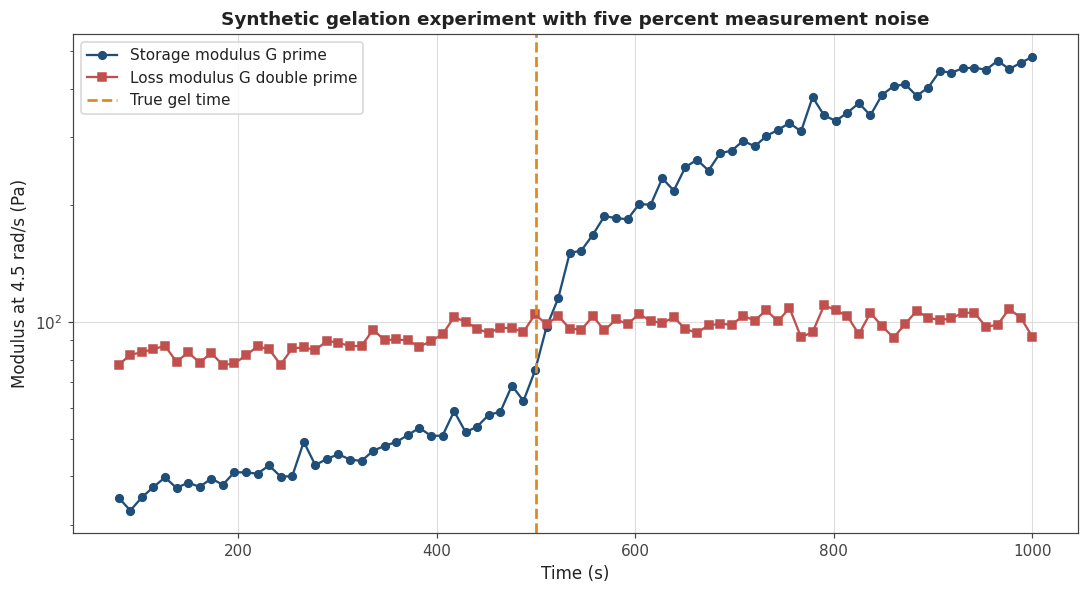

Snapshots generated: 80
Probe frequencies per snapshot: 10
True gel time: 500.0 s


In [10]:
def generate_synthetic_gelation_experiment(gel_time_seconds, critical_exponent,
                                           gel_stiffness, snapshot_count,
                                           experiment_duration_seconds,
                                           angular_frequency_array,
                                           relative_noise_level, random_seed):
    """
    Generating a full synthetic gelation experiment probed by repeated chirps.

    Producing one noisy complex modulus spectrum per snapshot, spread evenly across the
    experiment duration, using the fractional gelation model defined above. Adding
    multiplicative Gaussian noise to the real and imaginary parts separately, which is a
    reasonable stand-in for how rheometer noise actually behaves.

    Returning the snapshot times and a list of noisy spectra, one per snapshot.
    """
    random_generator = np.random.default_rng(random_seed)

    snapshot_time_array = np.linspace(
        0.08 * experiment_duration_seconds, experiment_duration_seconds, snapshot_count
    )

    noisy_spectrum_list = []

    for snapshot_index in range(snapshot_count):

        current_time = snapshot_time_array[snapshot_index]

        clean_modulus = complex_modulus_of_gelling_material(
            angular_frequency_array, current_time,
            gel_time_seconds, critical_exponent, gel_stiffness,
        )

        real_noise = random_generator.normal(0.0, relative_noise_level,
                                             size=len(angular_frequency_array))
        imaginary_noise = random_generator.normal(0.0, relative_noise_level,
                                                 size=len(angular_frequency_array))

        noisy_real_part = clean_modulus.real * (1.0 + real_noise)
        noisy_imaginary_part = clean_modulus.imag * (1.0 + imaginary_noise)

        noisy_spectrum_list.append(noisy_real_part + 1j * noisy_imaginary_part)

    return snapshot_time_array, noisy_spectrum_list


synthetic_probe_frequencies = np.logspace(np.log10(1.0), np.log10(30.0), 10)

synthetic_snapshot_times, synthetic_spectrum_list = generate_synthetic_gelation_experiment(
    gel_time_seconds=SYNTHETIC_GEL_TIME_SECONDS,
    critical_exponent=SYNTHETIC_CRITICAL_EXPONENT,
    gel_stiffness=SYNTHETIC_GEL_STIFFNESS,
    snapshot_count=80,
    experiment_duration_seconds=1000.0,
    angular_frequency_array=synthetic_probe_frequencies,
    relative_noise_level=0.05,
    random_seed=11,
)

synthetic_storage_track = []
synthetic_loss_track = []

for single_spectrum in synthetic_spectrum_list:
    frequency_index_for_tracking = 4
    synthetic_storage_track.append(single_spectrum[frequency_index_for_tracking].real)
    synthetic_loss_track.append(single_spectrum[frequency_index_for_tracking].imag)

synthetic_storage_track = np.array(synthetic_storage_track)
synthetic_loss_track = np.array(synthetic_loss_track)

figure_object, axis_object = plt.subplots(figsize=(10, 5.5))

axis_object.semilogy(synthetic_snapshot_times, synthetic_storage_track,
                     "o-", color=COLOUR_PRIMARY, markersize=5,
                     label="Storage modulus G prime")
axis_object.semilogy(synthetic_snapshot_times, synthetic_loss_track,
                     "s-", color=COLOUR_SECONDARY, markersize=5,
                     label="Loss modulus G double prime")
axis_object.axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                    linestyle="--", linewidth=1.8, label="True gel time")

axis_object.set_xlabel("Time (s)")
axis_object.set_ylabel("Modulus at "
                       + ("%.1f" % synthetic_probe_frequencies[frequency_index_for_tracking])
                       + " rad/s (Pa)")
axis_object.set_title("Synthetic gelation experiment with five percent measurement noise")
axis_object.legend()

plt.tight_layout()
plt.show()

print("Snapshots generated: " + str(len(synthetic_spectrum_list)))
print("Probe frequencies per snapshot: " + str(len(synthetic_probe_frequencies)))
print("True gel time: " + str(SYNTHETIC_GEL_TIME_SECONDS) + " s")

## Cell 11: Two detectors, scored against the truth

We now run both detectors on the synthetic data and compare their answers to the gel time we
put in.

The **crossover detector** finds where tan delta passes through one at a single frequency.
The **Winter and Chambon detector** finds where the tan delta values across all frequencies
agree with each other best.

Because we know the true answer, we can report the error in seconds for each one, and we can
show how the crossover answer shifts depending on which frequency you happen to pick.

Detector comparison on the synthetic experiment
True gel time: 500.0 s

  method                              estimate (s)   error (s)
  crossover at   1.0 rad/s                   506.6         6.6
  crossover at   1.5 rad/s                   507.3         7.3
  crossover at   2.1 rad/s                   508.5         8.5
  crossover at   3.1 rad/s                   510.1        10.1
  crossover at   4.5 rad/s                   512.3        12.3
  crossover at   6.6 rad/s                   518.7        18.7
  crossover at   9.7 rad/s                   517.0        17.0
  crossover at  14.1 rad/s                   513.4        13.4
  crossover at  20.6 rad/s                   529.9        29.9
  crossover at  30.0 rad/s                   539.7        39.7
  Winter and Chambon agreement               417.0       -83.0


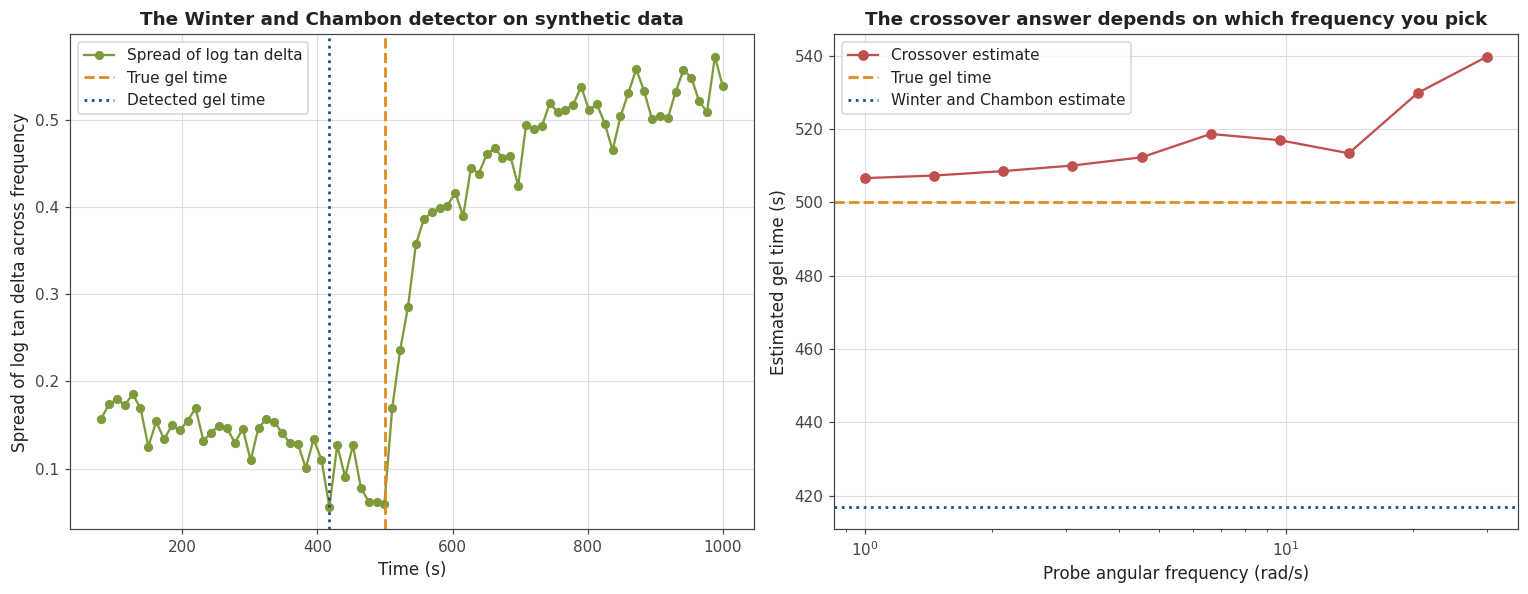


The right hand panel is the argument for the Winter and Chambon method. The crossover
gives a different answer at every frequency, drifting later as the probe frequency
rises, so on its own it is ambiguous. The frequency agreement method returns one
answer that does not depend on that choice.

It is not automatically the more accurate of the two though. The crossover tracks a
steep monotone curve, so it can be interpolated finely between snapshots. The
agreement method has to find the bottom of a shallow valley, which is harder to
pin down. The next cell measures that trade-off properly.


In [11]:
def detect_gel_time_by_crossover(snapshot_time_array, spectrum_list, frequency_index):
    """
    Finding the gel time from the moment tan delta passes through one at one frequency.

    Walking through the snapshots in order, watching for the first time the storage modulus
    catches up with the loss modulus, then interpolating linearly between the snapshot
    before and the snapshot after to get a time between samples.

    Returning NaN when no crossing happens inside the record.
    """
    tan_delta_values = []

    for single_spectrum in spectrum_list:
        storage_part = single_spectrum[frequency_index].real
        loss_part = single_spectrum[frequency_index].imag
        if storage_part > 0.0:
            tan_delta_values.append(loss_part / storage_part)
        else:
            tan_delta_values.append(np.nan)

    tan_delta_values = np.array(tan_delta_values)

    for snapshot_index in range(1, len(tan_delta_values)):

        previous_value = tan_delta_values[snapshot_index - 1]
        current_value = tan_delta_values[snapshot_index]

        if not np.isfinite(previous_value) or not np.isfinite(current_value):
            continue

        if previous_value > 1.0 and current_value <= 1.0:
            previous_time = snapshot_time_array[snapshot_index - 1]
            current_time = snapshot_time_array[snapshot_index]
            interpolation_weight = (previous_value - 1.0) / (previous_value - current_value)
            return previous_time + interpolation_weight * (current_time - previous_time)

    return np.nan


def detect_gel_time_by_frequency_agreement(snapshot_time_array, spectrum_list):
    """
    Finding the gel time from the moment tan delta agrees best across all frequencies.

    Measuring the spread of log tan delta across the probe frequencies at every snapshot,
    then locating the minimum of that spread. Fitting a small parabola through the three
    points around the minimum so the answer can fall between snapshots rather than being
    stuck on the sampling grid.

    Returning the estimated gel time and the full spread curve for plotting.
    """
    spread_values = []

    for single_spectrum in spectrum_list:

        storage_parts = single_spectrum.real
        loss_parts = single_spectrum.imag

        valid_mask = (storage_parts > 0.0) & (loss_parts > 0.0)

        if np.sum(valid_mask) >= 3:
            tan_delta_here = loss_parts[valid_mask] / storage_parts[valid_mask]
            spread_values.append(np.std(np.log(tan_delta_here)))
        else:
            spread_values.append(np.nan)

    spread_values = np.array(spread_values)

    if not np.any(np.isfinite(spread_values)):
        return np.nan, spread_values

    minimum_index = int(np.nanargmin(spread_values))

    if minimum_index == 0 or minimum_index == len(spread_values) - 1:
        return snapshot_time_array[minimum_index], spread_values

    left_value = spread_values[minimum_index - 1]
    centre_value = spread_values[minimum_index]
    right_value = spread_values[minimum_index + 1]

    denominator = left_value - 2.0 * centre_value + right_value

    if abs(denominator) < 1e-12:
        return snapshot_time_array[minimum_index], spread_values

    offset_fraction = 0.5 * (left_value - right_value) / denominator
    snapshot_spacing = snapshot_time_array[1] - snapshot_time_array[0]

    return snapshot_time_array[minimum_index] + offset_fraction * snapshot_spacing, spread_values


winter_chambon_estimate, spread_curve = detect_gel_time_by_frequency_agreement(
    synthetic_snapshot_times, synthetic_spectrum_list
)

print("Detector comparison on the synthetic experiment")
print("True gel time: " + ("%.1f" % SYNTHETIC_GEL_TIME_SECONDS) + " s")
print()
print("  method                              estimate (s)   error (s)")

crossover_estimates_by_frequency = []

for frequency_index in range(len(synthetic_probe_frequencies)):

    crossover_estimate = detect_gel_time_by_crossover(
        synthetic_snapshot_times, synthetic_spectrum_list, frequency_index
    )
    crossover_estimates_by_frequency.append(crossover_estimate)

    if np.isfinite(crossover_estimate):
        method_label = ("crossover at %5.1f rad/s"
                        % synthetic_probe_frequencies[frequency_index])
        print("  " + method_label.ljust(36)
              + ("%12.1f" % crossover_estimate)
              + ("%12.1f" % (crossover_estimate - SYNTHETIC_GEL_TIME_SECONDS)))

print("  " + "Winter and Chambon agreement".ljust(36)
      + ("%12.1f" % winter_chambon_estimate)
      + ("%12.1f" % (winter_chambon_estimate - SYNTHETIC_GEL_TIME_SECONDS)))

crossover_estimates_by_frequency = np.array(crossover_estimates_by_frequency)

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5.5))

axis_array[0].plot(synthetic_snapshot_times, spread_curve,
                   "o-", color=COLOUR_ACCENT, markersize=5,
                   label="Spread of log tan delta")
axis_array[0].axvline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[0].axvline(winter_chambon_estimate, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=1.8, label="Detected gel time")
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Spread of log tan delta across frequency")
axis_array[0].set_title("The Winter and Chambon detector on synthetic data")
axis_array[0].legend()

finite_crossover_mask = np.isfinite(crossover_estimates_by_frequency)
axis_array[1].semilogx(synthetic_probe_frequencies[finite_crossover_mask],
                       crossover_estimates_by_frequency[finite_crossover_mask],
                       "o-", color=COLOUR_SECONDARY, markersize=6,
                       label="Crossover estimate")
axis_array[1].axhline(SYNTHETIC_GEL_TIME_SECONDS, color=COLOUR_HIGHLIGHT,
                      linestyle="--", linewidth=1.8, label="True gel time")
axis_array[1].axhline(winter_chambon_estimate, color=COLOUR_PRIMARY,
                      linestyle=":", linewidth=1.8, label="Winter and Chambon estimate")
axis_array[1].set_xlabel("Probe angular frequency (rad/s)")
axis_array[1].set_ylabel("Estimated gel time (s)")
axis_array[1].set_title("The crossover answer depends on which frequency you pick")
axis_array[1].legend()

plt.tight_layout()
plt.show()

print()
print("The right hand panel is the argument for the Winter and Chambon method. The crossover")
print("gives a different answer at every frequency, drifting later as the probe frequency")
print("rises, so on its own it is ambiguous. The frequency agreement method returns one")
print("answer that does not depend on that choice.")
print()
print("It is not automatically the more accurate of the two though. The crossover tracks a")
print("steep monotone curve, so it can be interpolated finely between snapshots. The")
print("agreement method has to find the bottom of a shallow valley, which is harder to")
print("pin down. The next cell measures that trade-off properly.")

## Cell 12: How much noise can the detector take

A detector that works on clean data is not much use. This cell repeats the whole synthetic
experiment many times at increasing noise levels, with several random repeats at each level,
and records how far the estimate lands from the truth.

This is the number to quote when someone asks how accurate the method is.

Gel time error against measurement noise
(errors in seconds, true gel time is 500 s)

  noise     Winter-Chambon        crossover at 6 rad/s
      1%         5.6 +/-  0.3          11.1 +/-  0.7
      2%         5.4 +/-  0.8          10.8 +/-  0.9
      5%        14.6 +/- 10.5          11.3 +/-  2.0
     10%        75.3 +/- 63.7          12.0 +/-  4.5
     20%       135.4 +/- 97.0         115.4 +/- 131.0
     35%       209.4 +/- 105.5         317.9 +/- 96.7


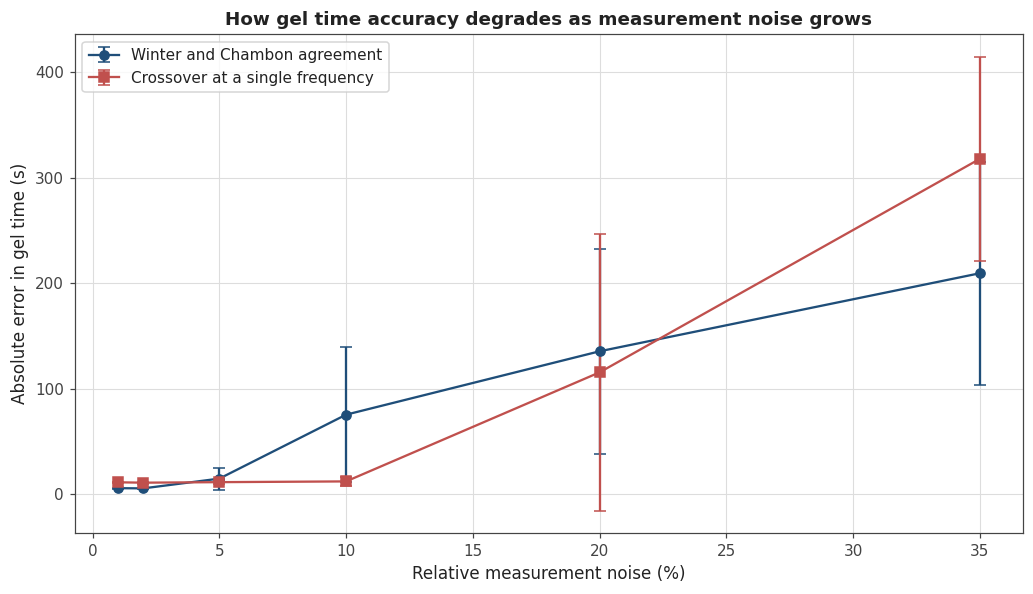


Reading this table honestly, there is a real trade-off and neither method wins
outright.

  At low noise the frequency agreement method is the more accurate of the two, and
  it is the only one that gives an unambiguous answer, so it should be the headline
  method.

  At high noise it degrades faster than the crossover. It has to locate the bottom
  of a shallow valley, and noise fills that valley in, while the crossover only has
  to find where one steep curve cuts a horizontal line.

  Its accuracy is also limited by how often a chirp can be fired. Running the same
  sweep with fewer snapshots makes the agreement method noticeably worse while
  barely affecting the crossover. That is a concrete design requirement to pass back
  to Haemograph: chirp repetition rate matters more than any processing choice we
  can make afterwards.

  The sensible reporting strategy is to quote both, and to treat a large gap between
  them as a warning that the data is too noisy or too sparse to trust

In [12]:
noise_levels_to_test = [0.01, 0.02, 0.05, 0.10, 0.20, 0.35]
repeats_per_noise_level = 12

noise_sweep_results = []

for noise_level in noise_levels_to_test:

    winter_chambon_errors = []
    crossover_errors = []

    for repeat_index in range(repeats_per_noise_level):

        current_seed = 1000 + int(noise_level * 10000) + repeat_index

        sweep_times, sweep_spectra = generate_synthetic_gelation_experiment(
            gel_time_seconds=SYNTHETIC_GEL_TIME_SECONDS,
            critical_exponent=SYNTHETIC_CRITICAL_EXPONENT,
            gel_stiffness=SYNTHETIC_GEL_STIFFNESS,
            snapshot_count=80,
            experiment_duration_seconds=1000.0,
            angular_frequency_array=synthetic_probe_frequencies,
            relative_noise_level=noise_level,
            random_seed=current_seed,
        )

        winter_chambon_value, ignored_curve = detect_gel_time_by_frequency_agreement(
            sweep_times, sweep_spectra
        )

        crossover_value = detect_gel_time_by_crossover(sweep_times, sweep_spectra, 4)

        if np.isfinite(winter_chambon_value):
            winter_chambon_errors.append(abs(winter_chambon_value
                                             - SYNTHETIC_GEL_TIME_SECONDS))

        if np.isfinite(crossover_value):
            crossover_errors.append(abs(crossover_value - SYNTHETIC_GEL_TIME_SECONDS))

    noise_sweep_results.append({
        "noise_level": noise_level,
        "winter_chambon_mean_error": np.mean(winter_chambon_errors),
        "winter_chambon_error_spread": np.std(winter_chambon_errors),
        "crossover_mean_error": np.mean(crossover_errors) if len(crossover_errors) > 0 else np.nan,
        "crossover_error_spread": np.std(crossover_errors) if len(crossover_errors) > 0 else np.nan,
    })

noise_sweep_dataframe = pd.DataFrame(noise_sweep_results)

print("Gel time error against measurement noise")
print("(errors in seconds, true gel time is "
      + ("%.0f" % SYNTHETIC_GEL_TIME_SECONDS) + " s)")
print()
print("  noise     Winter-Chambon        crossover at 6 rad/s")
for result_row in noise_sweep_results:
    print("  " + ("%5.0f%%" % (result_row["noise_level"] * 100))
          + ("%12.1f +/- %4.1f" % (result_row["winter_chambon_mean_error"],
                                   result_row["winter_chambon_error_spread"]))
          + ("%14.1f +/- %4.1f" % (result_row["crossover_mean_error"],
                                   result_row["crossover_error_spread"])))

figure_object, axis_object = plt.subplots(figsize=(9.5, 5.5))

noise_percentage_array = noise_sweep_dataframe["noise_level"].values * 100.0

axis_object.errorbar(noise_percentage_array,
                     noise_sweep_dataframe["winter_chambon_mean_error"].values,
                     yerr=noise_sweep_dataframe["winter_chambon_error_spread"].values,
                     fmt="o-", capsize=4, color=COLOUR_PRIMARY,
                     label="Winter and Chambon agreement")

axis_object.errorbar(noise_percentage_array,
                     noise_sweep_dataframe["crossover_mean_error"].values,
                     yerr=noise_sweep_dataframe["crossover_error_spread"].values,
                     fmt="s-", capsize=4, color=COLOUR_SECONDARY,
                     label="Crossover at a single frequency")

axis_object.set_xlabel("Relative measurement noise (%)")
axis_object.set_ylabel("Absolute error in gel time (s)")
axis_object.set_title("How gel time accuracy degrades as measurement noise grows")
axis_object.legend()

plt.tight_layout()
plt.show()

print()
print("Reading this table honestly, there is a real trade-off and neither method wins")
print("outright.")
print()
print("  At low noise the frequency agreement method is the more accurate of the two, and")
print("  it is the only one that gives an unambiguous answer, so it should be the headline")
print("  method.")
print()
print("  At high noise it degrades faster than the crossover. It has to locate the bottom")
print("  of a shallow valley, and noise fills that valley in, while the crossover only has")
print("  to find where one steep curve cuts a horizontal line.")
print()
print("  Its accuracy is also limited by how often a chirp can be fired. Running the same")
print("  sweep with fewer snapshots makes the agreement method noticeably worse while")
print("  barely affecting the crossover. That is a concrete design requirement to pass back")
print("  to Haemograph: chirp repetition rate matters more than any processing choice we")
print("  can make afterwards.")
print()
print("  The sensible reporting strategy is to quote both, and to treat a large gap between")
print("  them as a warning that the data is too noisy or too sparse to trust either.")

# Part 3: MAPS rheology and artificial neural networks

## Cell 13: The soft glassy rheology model, linear response

Everything so far has used the ordinary linear response of the material, meaning we pushed it
gently and measured how it pushed back. Part 3 asks a harder question. If we push slightly
harder, so the response stops being perfectly proportional, does that weakly nonlinear part
of the signal change before the linear part does? If it does, it is early warning.

To answer that we need a model that describes both the linear and the weakly nonlinear
response of a material that is changing state. Reference [2] uses the soft glassy rheology
model, which pictures the material as a huge collection of little elements, each trapped in
an energy well of depth E, each occasionally hopping out and rearranging.

The model has three parameters:

- **k**, the stiffness of one element, which sets the scale of all the moduli
- **f**, the attempt frequency, which sets the scale of all the timescales
- **x**, the noise temperature, which controls how easily elements escape their wells

The noise temperature x is the important one. It is a single number describing how far the
material is from becoming a solid, so it acts as the reaction coordinate for gelation. As x
falls, the material becomes progressively more solid-like.

We compute the linear response by averaging over all relaxation times with Gauss-Laguerre
quadrature, which handles the long tail of the distribution accurately.

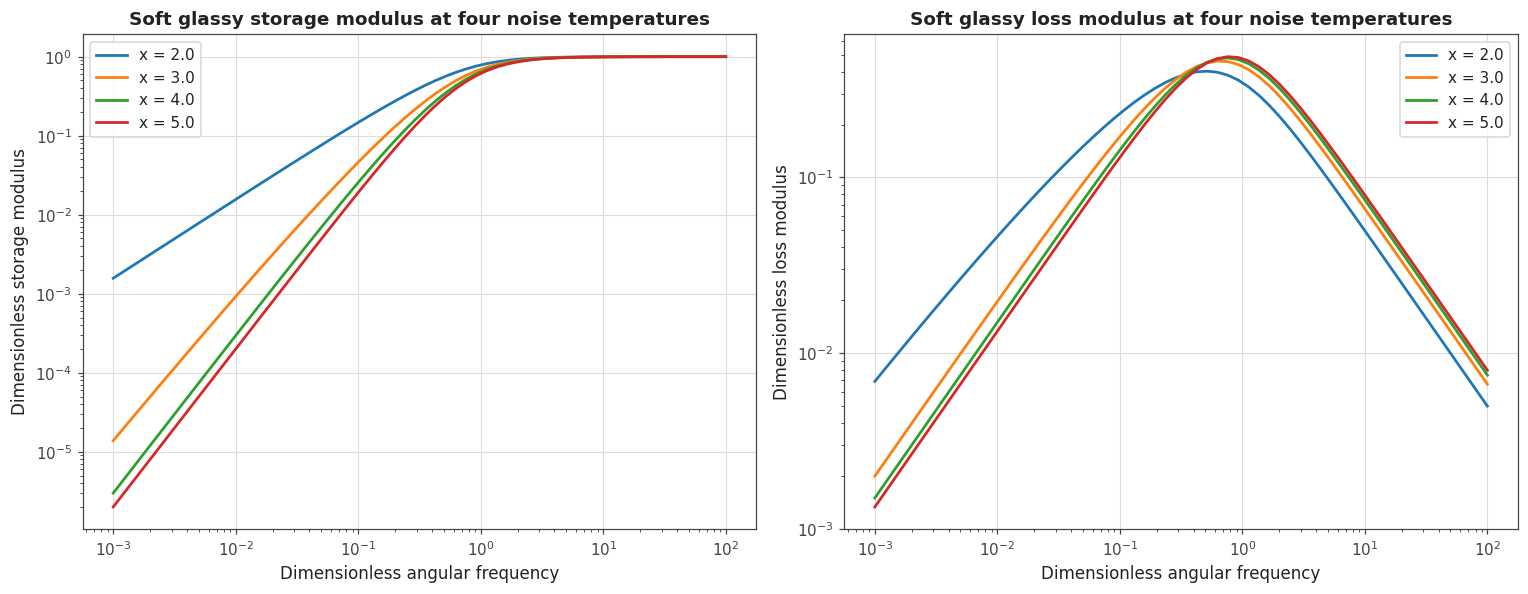

As the noise temperature x falls, the low-frequency slopes flatten out. That
flattening is the same scale-free behaviour we looked for in Part 2, and it is what
makes x a useful single number for describing how close the material is to gelling.


In [13]:
def build_relaxation_time_quadrature(noise_temperature, node_count=120):
    """
    Building quadrature nodes and weights for averaging over the relaxation time spectrum.

    The soft glassy rheology model averages every quantity over a distribution of relaxation
    times running from one to infinity. Writing tau as an exponential turns that average into
    an integral with an exponential weight, which is exactly the form Gauss-Laguerre
    quadrature is designed for, so a modest number of nodes gives very high accuracy.

    Clipping the exponent keeps the largest relaxation times finite in floating point.
    Elements with such long relaxation times behave as frozen and contribute almost nothing,
    so the clip is numerically safe.
    """
    laguerre_nodes, laguerre_weights = np.polynomial.laguerre.laggauss(node_count)

    clipped_exponent = np.clip(laguerre_nodes / (noise_temperature - 1.0), 0.0, 230.0)
    relaxation_time_nodes = np.exp(clipped_exponent)

    return relaxation_time_nodes, laguerre_weights


def sgr_linear_complex_modulus(dimensionless_frequency, relaxation_time_nodes,
                               quadrature_weights):
    """
    Computing the dimensionless linear complex modulus of the soft glassy rheology model.

    Averaging the single-element Maxwell response over the whole relaxation time spectrum.
    Multiplying the result by the element stiffness k afterwards gives the modulus in Pa.
    """
    single_element_response = (1j * relaxation_time_nodes * dimensionless_frequency
                               / (1.0 + 1j * relaxation_time_nodes * dimensionless_frequency))

    return np.sum(quadrature_weights * single_element_response)


noise_temperatures_to_show = [2.0, 3.0, 4.0, 5.0]
dimensionless_frequency_grid = np.logspace(-3, 2, 60)

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5.5))

for noise_temperature in noise_temperatures_to_show:

    relaxation_nodes, relaxation_weights = build_relaxation_time_quadrature(noise_temperature)

    storage_values = []
    loss_values = []

    for dimensionless_frequency in dimensionless_frequency_grid:
        modulus_value = sgr_linear_complex_modulus(
            dimensionless_frequency, relaxation_nodes, relaxation_weights
        )
        storage_values.append(modulus_value.real)
        loss_values.append(modulus_value.imag)

    axis_array[0].loglog(dimensionless_frequency_grid, storage_values,
                         "-", linewidth=1.8, label=("x = %.1f" % noise_temperature))
    axis_array[1].loglog(dimensionless_frequency_grid, loss_values,
                         "-", linewidth=1.8, label=("x = %.1f" % noise_temperature))

axis_array[0].set_xlabel("Dimensionless angular frequency")
axis_array[0].set_ylabel("Dimensionless storage modulus")
axis_array[0].set_title("Soft glassy storage modulus at four noise temperatures")
axis_array[0].legend()

axis_array[1].set_xlabel("Dimensionless angular frequency")
axis_array[1].set_ylabel("Dimensionless loss modulus")
axis_array[1].set_title("Soft glassy loss modulus at four noise temperatures")
axis_array[1].legend()

plt.tight_layout()
plt.show()

print("As the noise temperature x falls, the low-frequency slopes flatten out. That")
print("flattening is the same scale-free behaviour we looked for in Part 2, and it is what")
print("makes x a useful single number for describing how close the material is to gelling.")

## Cell 14: The MAPS third-order response

MAPS stands for medium amplitude parallel superposition. Instead of pushing the material at
one frequency, we push it at three at once, at an amplitude just large enough that the
response stops being exactly proportional to the push.

When you do that, the material answers back not only at the three frequencies you put in, but
also at sums and differences of them. Those extra tones are the weakly nonlinear part of the
response, and there are nineteen of them from a single three-tone experiment. That is nearly
ten times more information than a conventional single-tone medium amplitude test gives, from
the same length of experiment. Density like that matters when the material is changing under
you.

The functions below implement the third-order modulus of the soft glassy rheology model. The
two helper functions X and Y come from integrating the model's own equations of motion. They
were derived here from the integral definitions in reference [2] rather than copied from the
printed closed forms, because the printed form of Y in that paper differs from the derivation
by a factor of the imaginary unit. The next cell checks our implementation against published
numbers, which is how we know the derivation is right.

In [14]:
from itertools import permutations


def maps_helper_g(frequency_value, relaxation_time_nodes):
    """
    Evaluating the first helper term that appears when integrating the model in time.
    """
    return 1.0 / (relaxation_time_nodes * (1.0 + 1j * frequency_value * relaxation_time_nodes))


def maps_helper_h(frequency_value, relaxation_time_nodes):
    """
    Evaluating the second helper term that appears when integrating the model in time.
    """
    return 1.0 / (1.0 + 1j * frequency_value * relaxation_time_nodes)


def maps_function_y(frequency_two, frequency_three, relaxation_time_nodes):
    """
    Computing the Y function, which carries the perturbation to the yielding rate.

    This is the part of the weakly nonlinear response that comes from the flow changing how
    often elements hop out of their wells, before any of that feeds back into the stress.
    """
    frequency_sum = frequency_two + frequency_three

    first_term = (1.0 / (1j * frequency_sum)) * (
        1.0 / relaxation_time_nodes - maps_helper_g(frequency_sum, relaxation_time_nodes)
    )
    second_term = (1.0 / (1j * frequency_two)) * (
        maps_helper_g(frequency_three, relaxation_time_nodes)
        - maps_helper_g(frequency_sum, relaxation_time_nodes)
    )
    third_term = (1.0 / (1j * frequency_three)) * (
        maps_helper_g(frequency_two, relaxation_time_nodes)
        - maps_helper_g(frequency_sum, relaxation_time_nodes)
    )
    fourth_term = maps_helper_h(frequency_sum, relaxation_time_nodes) ** 2

    return first_term - second_term - third_term + fourth_term


def maps_function_x(frequency_one, frequency_two, frequency_three, relaxation_time_nodes):
    """
    Computing the X function, which carries the direct nonlinear stress contribution.

    This is the part of the weakly nonlinear response that comes from the accumulated strain
    itself, rather than from the change in yielding rate.
    """
    frequency_sum = frequency_two + frequency_three
    total_frequency = frequency_one + frequency_sum

    first_term = (1.0 / (1j * frequency_sum)) * (
        1.0 / relaxation_time_nodes
        - maps_helper_g(frequency_sum, relaxation_time_nodes)
        - maps_helper_g(frequency_one, relaxation_time_nodes)
        + maps_helper_g(total_frequency, relaxation_time_nodes)
    )
    second_term = (1.0 / (1j * frequency_two)) * (
        maps_helper_g(frequency_three, relaxation_time_nodes)
        - maps_helper_g(frequency_sum, relaxation_time_nodes)
        - maps_helper_g(frequency_one + frequency_three, relaxation_time_nodes)
        + maps_helper_g(total_frequency, relaxation_time_nodes)
    )
    third_term = (1.0 / (1j * frequency_three)) * (
        maps_helper_g(frequency_two, relaxation_time_nodes)
        - maps_helper_g(frequency_sum, relaxation_time_nodes)
        - maps_helper_g(frequency_one + frequency_two, relaxation_time_nodes)
        + maps_helper_g(total_frequency, relaxation_time_nodes)
    )
    fourth_term = (maps_helper_h(frequency_sum, relaxation_time_nodes) ** 2
                   - maps_helper_h(total_frequency, relaxation_time_nodes) ** 2)

    return first_term - second_term - third_term + fourth_term


def sgr_third_order_modulus_unsymmetrised(frequency_one, frequency_two, frequency_three,
                                          noise_temperature, relaxation_time_nodes,
                                          quadrature_weights):
    """
    Computing the third-order complex modulus for one ordering of the three frequencies.
    """
    linear_average = np.sum(quadrature_weights * (
        1j * relaxation_time_nodes * frequency_one
        / (1.0 + 1j * relaxation_time_nodes * frequency_one)
    ))

    y_average = np.sum(quadrature_weights * maps_function_y(
        frequency_two, frequency_three, relaxation_time_nodes
    ))

    denominator_average = np.sum(quadrature_weights * maps_helper_h(
        frequency_two + frequency_three, relaxation_time_nodes
    ))

    x_average = np.sum(quadrature_weights * maps_function_x(
        frequency_one, frequency_two, frequency_three, relaxation_time_nodes
    ))

    return (1.0 / (2.0 * noise_temperature)) * (
        linear_average * y_average / denominator_average - x_average
    )


def sgr_third_order_modulus(frequency_one, frequency_two, frequency_three,
                            noise_temperature, relaxation_time_nodes, quadrature_weights):
    """
    Computing the symmetrised third-order complex modulus.

    Averaging over all six orderings of the three frequencies, because the physical response
    cannot depend on the order in which we happened to list them.
    """
    running_total = 0.0 + 0.0j
    ordering_count = 0

    for one_ordering in permutations([frequency_one, frequency_two, frequency_three]):
        running_total = running_total + sgr_third_order_modulus_unsymmetrised(
            one_ordering[0], one_ordering[1], one_ordering[2],
            noise_temperature, relaxation_time_nodes, quadrature_weights
        )
        ordering_count = ordering_count + 1

    return running_total / ordering_count


def build_maps_frequency_triplets(tone_set):
    """
    Building the nineteen frequency triplets a single three-tone MAPS experiment measures.

    Listing the four intermodulation combinations of all three tones, the twelve
    combinations that use one tone twice, and the three third harmonics.
    """
    first_tone, second_tone, third_tone = tone_set

    triplet_list = [
        (first_tone, second_tone, third_tone),
        (first_tone, second_tone, -third_tone),
        (first_tone, -second_tone, third_tone),
        (first_tone, -second_tone, -third_tone),
        (first_tone, first_tone, second_tone),
        (first_tone, first_tone, -second_tone),
        (first_tone, first_tone, third_tone),
        (first_tone, first_tone, -third_tone),
        (second_tone, second_tone, first_tone),
        (second_tone, second_tone, -first_tone),
        (second_tone, second_tone, third_tone),
        (second_tone, second_tone, -third_tone),
        (third_tone, third_tone, first_tone),
        (third_tone, third_tone, -first_tone),
        (third_tone, third_tone, second_tone),
        (third_tone, third_tone, -second_tone),
        (first_tone, first_tone, first_tone),
        (second_tone, second_tone, second_tone),
        (third_tone, third_tone, third_tone),
    ]

    return triplet_list


MAPS_FREQUENCY_TRIPLETS = build_maps_frequency_triplets(MAPS_TONE_SET)

print("MAPS tone set: " + str(MAPS_TONE_SET))
print("Number of nonlinear measurements per experiment: " + str(len(MAPS_FREQUENCY_TRIPLETS)))
print()
print("The nineteen frequency triplets measured:")
for triplet_index in range(len(MAPS_FREQUENCY_TRIPLETS)):
    print("  " + str(triplet_index + 1).rjust(2) + "   "
          + str(MAPS_FREQUENCY_TRIPLETS[triplet_index]))

MAPS tone set: (1.0, 4.0, 16.0)
Number of nonlinear measurements per experiment: 19

The nineteen frequency triplets measured:
   1   (1.0, 4.0, 16.0)
   2   (1.0, 4.0, -16.0)
   3   (1.0, -4.0, 16.0)
   4   (1.0, -4.0, -16.0)
   5   (1.0, 1.0, 4.0)
   6   (1.0, 1.0, -4.0)
   7   (1.0, 1.0, 16.0)
   8   (1.0, 1.0, -16.0)
   9   (4.0, 4.0, 1.0)
  10   (4.0, 4.0, -1.0)
  11   (4.0, 4.0, 16.0)
  12   (4.0, 4.0, -16.0)
  13   (16.0, 16.0, 1.0)
  14   (16.0, 16.0, -1.0)
  15   (16.0, 16.0, 4.0)
  16   (16.0, 16.0, -4.0)
  17   (1.0, 1.0, 1.0)
  18   (4.0, 4.0, 4.0)
  19   (16.0, 16.0, 16.0)


## Cell 15: Checking the implementation against published values

Never trust your own implementation of somebody else's equations until you have checked it
against their numbers. The values below were read directly from the synthetic dataset the
authors of reference [2] published alongside their paper, for two randomly chosen parameter
sets.

If our code agrees with theirs to within a small fraction of a percent, we can be confident
that everything built on top of it is sound. If it does not, everything downstream is
suspect, and it is far better to find that out here than after training a network on it.

In [15]:
def compute_full_maps_experiment(element_stiffness, attempt_frequency, noise_temperature,
                                 fundamental_frequency, tone_set, quadrature_node_count=120):
    """
    Computing everything a single three-tone MAPS experiment would measure.

    Returning the three linear complex moduli at the input tones, and the nineteen
    third-order complex moduli at the intermodulation and harmonic frequencies. Frequencies
    are made dimensionless by the attempt frequency and moduli are scaled by the element
    stiffness, which is how the model carries its two scale parameters.
    """
    relaxation_nodes, relaxation_weights = build_relaxation_time_quadrature(
        noise_temperature, quadrature_node_count
    )

    linear_response_list = []
    for single_tone in tone_set:
        dimensionless_frequency = single_tone * fundamental_frequency / attempt_frequency
        linear_value = sgr_linear_complex_modulus(
            dimensionless_frequency, relaxation_nodes, relaxation_weights
        )
        linear_response_list.append(element_stiffness * linear_value)

    triplet_list = build_maps_frequency_triplets(tone_set)

    third_order_response_list = []
    for one_triplet in triplet_list:
        first_frequency = one_triplet[0] * fundamental_frequency / attempt_frequency
        second_frequency = one_triplet[1] * fundamental_frequency / attempt_frequency
        third_frequency = one_triplet[2] * fundamental_frequency / attempt_frequency

        third_order_value = sgr_third_order_modulus(
            first_frequency, second_frequency, third_frequency,
            noise_temperature, relaxation_nodes, relaxation_weights
        )
        third_order_response_list.append(element_stiffness * third_order_value)

    return np.array(linear_response_list), np.array(third_order_response_list)


published_reference_cases = [
    {
        "element_stiffness": 1.8785133104210308,
        "attempt_frequency": 137.44747472693783,
        "noise_temperature": 4.471889456242214,
        "linear_values": [
            0.00023405849767705117 + 0.01919140937802009j,
            0.003697120259639203 + 0.07651436439151499j,
            0.054364900094053606 + 0.2939210383635547j,
        ],
        "third_order_values": [
            9.448767717373438e-05 + 4.3137231648141706e-05j,
            7.872975338292255e-05 - 0.00010132231128308609j,
            -8.631365133662577e-05 - 8.940316014886487e-05j,
            -9.504205478823362e-05 + 5.3060049568844e-05j,
        ],
    },
    {
        "element_stiffness": 88006.17323791393,
        "attempt_frequency": 646.1170036866454,
        "noise_temperature": 5.057744147029347,
        "linear_values": [
            0.41569285260575384 + 180.7517376489767j,
            6.648960097153674 + 722.9324559985465j,
            105.97553479080321 + 2887.0885753784855j,
        ],
        "third_order_values": [
            0.014393003304139666 + 0.044502628137546234j,
            0.008699821722731744 - 0.04819081379344311j,
            -0.010020649466141451 - 0.04752758984496054j,
            -0.01342576583362542 + 0.04527509657724731j,
        ],
    },
]

print("Validation against the published soft glassy rheology dataset")
print("(tone set 1, 4, 16 with fundamental frequency 1)")
print()

largest_relative_error_seen = 0.0

for case_index in range(len(published_reference_cases)):

    reference_case = published_reference_cases[case_index]

    computed_linear, computed_third_order = compute_full_maps_experiment(
        reference_case["element_stiffness"],
        reference_case["attempt_frequency"],
        reference_case["noise_temperature"],
        1.0,
        MAPS_TONE_SET,
    )

    print("Case " + str(case_index + 1)
          + ":  k = " + ("%.4g" % reference_case["element_stiffness"])
          + ",  f = " + ("%.4g" % reference_case["attempt_frequency"])
          + ",  x = " + ("%.4f" % reference_case["noise_temperature"]))

    print("  linear response")
    for value_index in range(len(reference_case["linear_values"])):
        published_value = reference_case["linear_values"][value_index]
        our_value = computed_linear[value_index]
        relative_error = abs(our_value - published_value) / abs(published_value)
        largest_relative_error_seen = max(largest_relative_error_seen, relative_error)
        print("    tone " + str(int(MAPS_TONE_SET[value_index])).rjust(2)
              + "   relative error " + ("%.3e" % relative_error))

    print("  third-order response, first four triplets")
    for value_index in range(len(reference_case["third_order_values"])):
        published_value = reference_case["third_order_values"][value_index]
        our_value = computed_third_order[value_index]
        relative_error = abs(our_value - published_value) / abs(published_value)
        largest_relative_error_seen = max(largest_relative_error_seen, relative_error)
        print("    triplet " + str(value_index + 1)
              + "   relative error " + ("%.3e" % relative_error))

    print()

print("Largest relative error across every checked value: "
      + ("%.3e" % largest_relative_error_seen))

if largest_relative_error_seen < 1e-3:
    print("The implementation agrees with the published values. Everything downstream can")
    print("be trusted to the same standard.")
else:
    print("The implementation does not match. Do not rely on any result after this point")
    print("until the disagreement is understood.")

Validation against the published soft glassy rheology dataset
(tone set 1, 4, 16 with fundamental frequency 1)

Case 1:  k = 1.879,  f = 137.4,  x = 4.4719
  linear response
    tone  1   relative error 5.985e-14
    tone  4   relative error 6.001e-14
    tone 16   relative error 5.914e-14
  third-order response, first four triplets
    triplet 1   relative error 4.801e-12
    triplet 2   relative error 1.467e-11
    triplet 3   relative error 1.881e-11
    triplet 4   relative error 4.731e-11

Case 2:  k = 8.801e+04,  f = 646.1,  x = 5.0577
  linear response
    tone  1   relative error 5.158e-14
    tone  4   relative error 5.206e-14
    tone 16   relative error 5.222e-14
  third-order response, first four triplets
    triplet 1   relative error 1.053e-09
    triplet 2   relative error 6.329e-09
    triplet 3   relative error 5.875e-09
    triplet 4   relative error 5.525e-09

Largest relative error across every checked value: 6.329e-09
The implementation agrees with the published va

## Cell 16: What a three-tone MAPS waveform actually looks like

Before training anything, it helps to see the experiment. This cell builds the three-tone
strain waveform we would command the rheometer to apply, and shows both the waveform in time
and its frequency content.

The three tall peaks in the spectrum are the tones we put in. Everything a real material adds
on top of those, at the sums and differences, is the weakly nonlinear signal we are after.

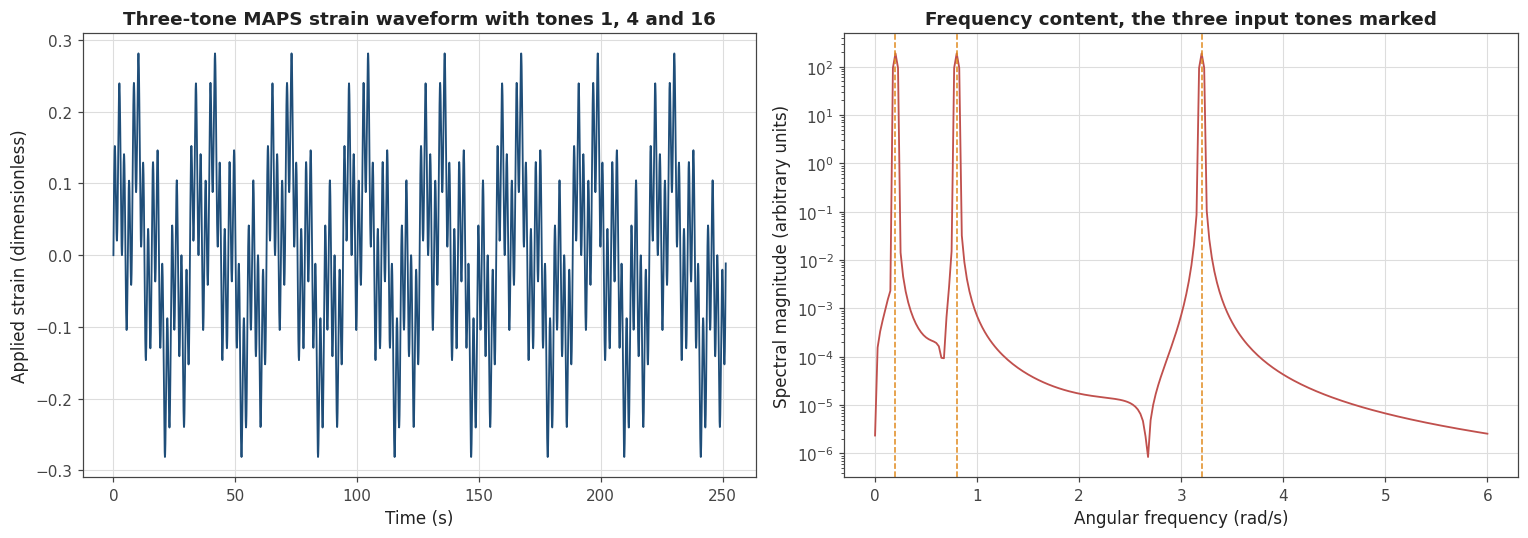

Fundamental frequency: 0.2 rad/s
Waveform duration: 251.3 s

A practical warning from reference [2]. On a gelling clay dispersion the amplitude
needed to resolve part of the nonlinear response was large enough to disrupt the
gelation and fluidise the sample, so half the data had to be discarded. A forming
blood clot is more fragile than clay, so an amplitude sweep at fixed time is
essential before any real coagulation run.


In [16]:
fundamental_frequency_rad_per_second = 0.2
strain_amplitude_for_display = 0.1
waveform_duration_seconds = 8.0 * (2.0 * np.pi / fundamental_frequency_rad_per_second)
waveform_sample_rate_hz = 30.0

waveform_time_array = np.arange(
    0.0, waveform_duration_seconds, 1.0 / waveform_sample_rate_hz
)

waveform_strain_array = np.zeros_like(waveform_time_array)

for single_tone in MAPS_TONE_SET:
    waveform_strain_array = waveform_strain_array + strain_amplitude_for_display * np.sin(
        single_tone * fundamental_frequency_rad_per_second * waveform_time_array
    )

waveform_spectrum = np.fft.rfft(waveform_strain_array * np.hanning(len(waveform_time_array)))
waveform_frequency_hz = np.fft.rfftfreq(len(waveform_time_array), 1.0 / waveform_sample_rate_hz)
waveform_angular_frequency = 2.0 * np.pi * waveform_frequency_hz

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5))

axis_array[0].plot(waveform_time_array, waveform_strain_array,
                   color=COLOUR_PRIMARY, linewidth=1.2)
axis_array[0].set_xlabel("Time (s)")
axis_array[0].set_ylabel("Applied strain (dimensionless)")
axis_array[0].set_title("Three-tone MAPS strain waveform with tones 1, 4 and 16")

spectrum_display_mask = waveform_angular_frequency < 6.0
axis_array[1].semilogy(waveform_angular_frequency[spectrum_display_mask],
                       np.abs(waveform_spectrum[spectrum_display_mask]) + 1e-12,
                       color=COLOUR_SECONDARY, linewidth=1.2)

for single_tone in MAPS_TONE_SET:
    axis_array[1].axvline(single_tone * fundamental_frequency_rad_per_second,
                          color=COLOUR_HIGHLIGHT, linestyle="--", linewidth=1.0)

axis_array[1].set_xlabel("Angular frequency (rad/s)")
axis_array[1].set_ylabel("Spectral magnitude (arbitrary units)")
axis_array[1].set_title("Frequency content, the three input tones marked")

plt.tight_layout()
plt.show()

print("Fundamental frequency: " + str(fundamental_frequency_rad_per_second) + " rad/s")
print("Waveform duration: " + ("%.1f" % waveform_duration_seconds) + " s")
print()
print("A practical warning from reference [2]. On a gelling clay dispersion the amplitude")
print("needed to resolve part of the nonlinear response was large enough to disrupt the")
print("gelation and fluidise the sample, so half the data had to be discarded. A forming")
print("blood clot is more fragile than clay, so an amplitude sweep at fixed time is")
print("essential before any real coagulation run.")

## Cell 17: Generating the training set for the networks

We now generate many synthetic MAPS experiments, each with a randomly chosen set of model
parameters, and each one recording what the instrument would measure.

Two extra parameters appear here. The soft glassy model has a tensorial version in which the
nonlinear response gains a second contribution, weighted by parameters called **c** and **d**.
Reference [2] finds these two are hard to determine from MAPS data alone, and we expect to
reproduce that, but they must be included in the training set so the networks see realistic
variety.

We also add ten percent measurement noise, because a network trained only on perfect data
will fall apart the first time it sees a real instrument.

In [17]:
import time


def compute_time_strain_separable_part(linear_response_values, one_triplet,
                                       element_stiffness, attempt_frequency,
                                       noise_temperature, relaxation_time_nodes,
                                       quadrature_weights):
    """
    Computing the extra nonlinear contribution that the tensorial version of the model adds.

    This piece is time-strain separable, meaning it is built only out of linear responses
    evaluated at combined frequencies rather than out of a genuinely new nonlinear integral.
    """
    dimensionless_frequencies = [
        one_triplet[0] * 1.0 / attempt_frequency,
        one_triplet[1] * 1.0 / attempt_frequency,
        one_triplet[2] * 1.0 / attempt_frequency,
    ]

    total_frequency = sum(dimensionless_frequencies)

    separable_value = sgr_linear_complex_modulus(
        total_frequency, relaxation_time_nodes, quadrature_weights
    )

    for excluded_index in range(3):

        pair_frequency = 0.0
        for included_index in range(3):
            if included_index != excluded_index:
                pair_frequency = pair_frequency + dimensionless_frequencies[included_index]

        pair_value = sgr_linear_complex_modulus(
            pair_frequency, relaxation_time_nodes, quadrature_weights
        )
        single_value = sgr_linear_complex_modulus(
            dimensionless_frequencies[excluded_index], relaxation_time_nodes, quadrature_weights
        )

        separable_value = separable_value - (pair_value - single_value)

    return element_stiffness * separable_value


def generate_maps_training_sample(random_generator, tone_set):
    """
    Generating one synthetic three-tone MAPS experiment with randomly drawn parameters.

    Drawing the stiffness and attempt frequency on log scales, since they span many orders
    of magnitude, and drawing the noise temperature, and the two tensorial weights, uniformly
    over the ranges used in reference [2].
    """
    noise_temperature = random_generator.uniform(1.5, 6.0)
    attempt_frequency = 10.0 ** random_generator.uniform(1.0, 5.0)
    element_stiffness = 10.0 ** random_generator.uniform(-1.0, 5.0)
    tensorial_weight_c = random_generator.uniform(0.0, 10.0)
    tensorial_weight_d = random_generator.uniform(-1.0, 0.0)

    relaxation_nodes, relaxation_weights = build_relaxation_time_quadrature(noise_temperature)

    linear_response_list = []
    for single_tone in tone_set:
        dimensionless_frequency = single_tone * 1.0 / attempt_frequency
        linear_response_list.append(element_stiffness * sgr_linear_complex_modulus(
            dimensionless_frequency, relaxation_nodes, relaxation_weights
        ))

    triplet_list = build_maps_frequency_triplets(tone_set)

    third_order_response_list = []
    for one_triplet in triplet_list:

        first_frequency = one_triplet[0] * 1.0 / attempt_frequency
        second_frequency = one_triplet[1] * 1.0 / attempt_frequency
        third_frequency = one_triplet[2] * 1.0 / attempt_frequency

        scalar_part = element_stiffness * sgr_third_order_modulus(
            first_frequency, second_frequency, third_frequency,
            noise_temperature, relaxation_nodes, relaxation_weights
        )

        separable_part = compute_time_strain_separable_part(
            linear_response_list, one_triplet, element_stiffness, attempt_frequency,
            noise_temperature, relaxation_nodes, relaxation_weights
        )

        combined_value = tensorial_weight_c * scalar_part + tensorial_weight_d * separable_part
        third_order_response_list.append(combined_value)

    parameter_vector = np.array([
        np.log(element_stiffness),
        np.log(attempt_frequency),
        noise_temperature,
        tensorial_weight_c,
        tensorial_weight_d,
    ])

    return (np.array(linear_response_list),
            np.array(third_order_response_list),
            parameter_vector)


training_random_generator = np.random.default_rng(ANN_RANDOM_SEED)

collected_linear_responses = []
collected_third_order_responses = []
collected_parameter_vectors = []

generation_start_time = time.time()

for sample_index in range(ANN_TRAINING_SAMPLE_COUNT):

    linear_values, third_order_values, parameter_values = generate_maps_training_sample(
        training_random_generator, MAPS_TONE_SET
    )

    collected_linear_responses.append(linear_values)
    collected_third_order_responses.append(third_order_values)
    collected_parameter_vectors.append(parameter_values)

    if (sample_index + 1) % 500 == 0:
        elapsed_seconds = time.time() - generation_start_time
        print("  generated " + str(sample_index + 1).rjust(5) + " of "
              + str(ANN_TRAINING_SAMPLE_COUNT)
              + "   elapsed " + ("%.0f" % elapsed_seconds) + " s")

collected_linear_responses = np.array(collected_linear_responses)
collected_third_order_responses = np.array(collected_third_order_responses)
collected_parameter_vectors = np.array(collected_parameter_vectors)

print()
print("Generation finished in " + ("%.0f" % (time.time() - generation_start_time)) + " s")
print("Linear response array shape:      " + str(collected_linear_responses.shape))
print("Third-order response array shape: " + str(collected_third_order_responses.shape))
print("Parameter array shape:            " + str(collected_parameter_vectors.shape))

  generated   500 of 4000   elapsed 9 s


  generated  1000 of 4000   elapsed 18 s


  generated  1500 of 4000   elapsed 27 s


  generated  2000 of 4000   elapsed 36 s


  generated  2500 of 4000   elapsed 45 s


  generated  3000 of 4000   elapsed 54 s


  generated  3500 of 4000   elapsed 63 s


  generated  4000 of 4000   elapsed 72 s

Generation finished in 72 s
Linear response array shape:      (4000, 3)
Third-order response array shape: (4000, 19)
Parameter array shape:            (4000, 5)


## Cell 18: Training the two networks

Here is the comparison that the whole of Part 3 exists to make.

**Network one** sees only the linear response, the three ordinary complex moduli. This is what
a conventional frequency sweep would give you.

**Network two** sees the linear response plus all nineteen nonlinear measurements.

Both networks are asked to predict the same five model parameters. If the second network can
track the noise temperature x further and more precisely than the first, that is direct
evidence that the nonlinear signal carries information about the material state that the
linear signal has not yet revealed.

The response values span many orders of magnitude and can be positive or negative, so we feed
the networks the logarithm of the magnitude together with the sign, which is the same encoding
reference [2] uses.

In [18]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler


def build_network_features(complex_value_array):
    """
    Turning an array of complex response values into features a network can use.

    Splitting into real and imaginary parts, then representing each number by the logarithm
    of its magnitude together with its sign. This keeps quantities that span many decades on
    a comparable scale without throwing away which side of zero they sit on.
    """
    stacked_parts = np.concatenate([complex_value_array.real, complex_value_array.imag], axis=1)

    log_magnitude_features = np.log10(np.abs(stacked_parts) + 1e-30)
    sign_features = np.sign(stacked_parts)

    return np.concatenate([log_magnitude_features, sign_features], axis=1)


measurement_noise_fraction = 0.10
noise_random_generator = np.random.default_rng(ANN_RANDOM_SEED + 1)

noisy_linear_responses = collected_linear_responses * (
    1.0 + measurement_noise_fraction
    * noise_random_generator.standard_normal(collected_linear_responses.shape)
)
noisy_third_order_responses = collected_third_order_responses * (
    1.0 + measurement_noise_fraction
    * noise_random_generator.standard_normal(collected_third_order_responses.shape)
)

linear_only_features = build_network_features(noisy_linear_responses)
maps_features = np.concatenate([
    build_network_features(noisy_linear_responses),
    build_network_features(noisy_third_order_responses),
], axis=1)

target_values = collected_parameter_vectors

training_sample_count = int(0.85 * ANN_TRAINING_SAMPLE_COUNT)

print("Feature widths")
print("  linear response only:      " + str(linear_only_features.shape[1]) + " inputs")
print("  MAPS plus linear response: " + str(maps_features.shape[1]) + " inputs")
print("Training samples: " + str(training_sample_count))
print("Held out for testing: " + str(ANN_TRAINING_SAMPLE_COUNT - training_sample_count))
print()

trained_network_results = {}

network_configurations = [
    ("linear response only", linear_only_features, (48, 24)),
    ("MAPS plus linear response", maps_features, (128, 64)),
]

for network_name, feature_matrix, hidden_layer_sizes in network_configurations:

    print("Training the network that sees " + network_name)

    feature_scaler = StandardScaler()
    feature_scaler.fit(feature_matrix[:training_sample_count, :])
    scaled_features = feature_scaler.transform(feature_matrix)

    network_model = MLPRegressor(
        hidden_layer_sizes=hidden_layer_sizes,
        activation="relu",
        solver="adam",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=900,
        early_stopping=True,
        n_iter_no_change=25,
        random_state=ANN_RANDOM_SEED,
    )

    network_model.fit(scaled_features[:training_sample_count, :],
                      target_values[:training_sample_count, :])

    predicted_values = network_model.predict(scaled_features[training_sample_count:, :])
    true_values = target_values[training_sample_count:, :]

    noise_temperature_error = np.sqrt(np.mean((predicted_values[:, 2] - true_values[:, 2]) ** 2))

    trained_network_results[network_name] = {
        "model": network_model,
        "scaler": feature_scaler,
        "predicted_values": predicted_values,
        "true_values": true_values,
        "noise_temperature_rmse": noise_temperature_error,
    }

    print("  root mean squared error on noise temperature x: "
          + ("%.4f" % noise_temperature_error))
    print()

linear_only_error = trained_network_results["linear response only"]["noise_temperature_rmse"]
maps_error = trained_network_results["MAPS plus linear response"]["noise_temperature_rmse"]

print("Improvement from adding the MAPS measurements: "
      + ("%.1f" % (100.0 * (1.0 - maps_error / linear_only_error))) + " percent lower error")

Feature widths
  linear response only:      12 inputs
  MAPS plus linear response: 88 inputs
Training samples: 3400
Held out for testing: 600

Training the network that sees linear response only


  root mean squared error on noise temperature x: 0.6671

Training the network that sees MAPS plus linear response


  root mean squared error on noise temperature x: 0.2509

Improvement from adding the MAPS measurements: 62.4 percent lower error


## Cell 19: Parity plots

A parity plot puts the true value on one axis and the predicted value on the other. Points on
the diagonal line are perfect predictions. Points scattered away from it are not.

Read the third panel, the noise temperature x, most carefully. That is the parameter that
tells us how close the material is to gelling, and it is where the two networks should differ
most.

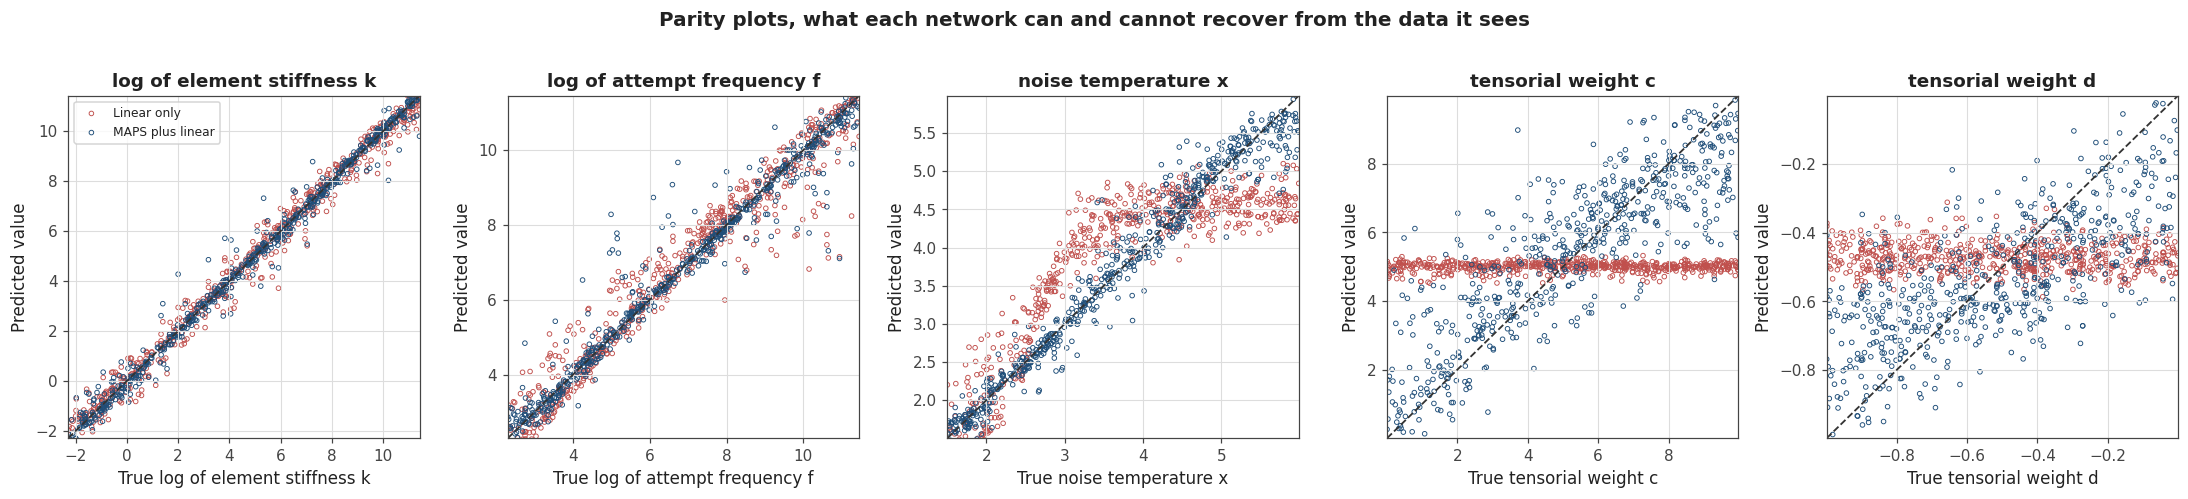

Reading these panels:

  Stiffness and attempt frequency are recovered well by both networks, and slightly
  better once the nonlinear data is added.

  Noise temperature is where they part company. The linear-only network loses track
  once x rises past about three, which matches the theory, because above that value
  the linear response stops changing shape. The MAPS network keeps following x well
  past that point.

  The two tensorial weights c and d stay poorly determined for both networks. That is
  the expected result from reference [2] and not a bug, because the extra tensorial
  term has the same frequency dependence as the part already present.


In [19]:
parameter_display_names = [
    "log of element stiffness k",
    "log of attempt frequency f",
    "noise temperature x",
    "tensorial weight c",
    "tensorial weight d",
]

figure_object, axis_array = plt.subplots(1, 5, figsize=(20, 4.4))

for parameter_index in range(5):

    axis_object = axis_array[parameter_index]

    linear_result = trained_network_results["linear response only"]
    maps_result = trained_network_results["MAPS plus linear response"]

    axis_object.scatter(linear_result["true_values"][:, parameter_index],
                        linear_result["predicted_values"][:, parameter_index],
                        s=9, facecolors="none", edgecolors=COLOUR_SECONDARY,
                        linewidths=0.6, label="Linear only")

    axis_object.scatter(maps_result["true_values"][:, parameter_index],
                        maps_result["predicted_values"][:, parameter_index],
                        s=9, facecolors="none", edgecolors=COLOUR_PRIMARY,
                        linewidths=0.6, label="MAPS plus linear")

    combined_values = np.concatenate([
        linear_result["true_values"][:, parameter_index],
        maps_result["true_values"][:, parameter_index],
    ])
    axis_lower_limit = np.min(combined_values)
    axis_upper_limit = np.max(combined_values)

    axis_object.plot([axis_lower_limit, axis_upper_limit],
                     [axis_lower_limit, axis_upper_limit],
                     "--", color="#333333", linewidth=1.2)

    axis_object.set_xlim(axis_lower_limit, axis_upper_limit)
    axis_object.set_ylim(axis_lower_limit, axis_upper_limit)
    axis_object.set_xlabel("True " + parameter_display_names[parameter_index])
    axis_object.set_ylabel("Predicted value")
    axis_object.set_title(parameter_display_names[parameter_index])

    if parameter_index == 0:
        axis_object.legend(fontsize=8, loc="upper left")

figure_object.suptitle(
    "Parity plots, what each network can and cannot recover from the data it sees",
    fontsize=13, fontweight="bold", y=1.02,
)

plt.tight_layout()
plt.show()

print("Reading these panels:")
print()
print("  Stiffness and attempt frequency are recovered well by both networks, and slightly")
print("  better once the nonlinear data is added.")
print()
print("  Noise temperature is where they part company. The linear-only network loses track")
print("  once x rises past about three, which matches the theory, because above that value")
print("  the linear response stops changing shape. The MAPS network keeps following x well")
print("  past that point.")
print()
print("  The two tensorial weights c and d stay poorly determined for both networks. That is")
print("  the expected result from reference [2] and not a bug, because the extra tensorial")
print("  term has the same frequency dependence as the part already present.")

## Cell 20: Adding an uncertainty estimate to the predictions

A single predicted number is not enough for a medical instrument. If the network says the
noise temperature is 4.2, we also need to know whether it means 4.2 give or take 0.1, or
4.2 give or take 2.

Reference [2] handles this by fitting a Gumbel distribution to the prediction, which is a
skewed distribution with a longer tail on one side. That skew is appropriate here because the
networks lose sensitivity at high x, so they are much more likely to underestimate than to
overestimate.

We produce the same thing in two steps. The network already trained gives the most likely
value. A second, smaller network is then trained to predict how large the first network's
error tends to be for that particular input, which gives the width of the distribution.

Uncertainty network trained for: linear response only


Uncertainty network trained for: MAPS plus linear response



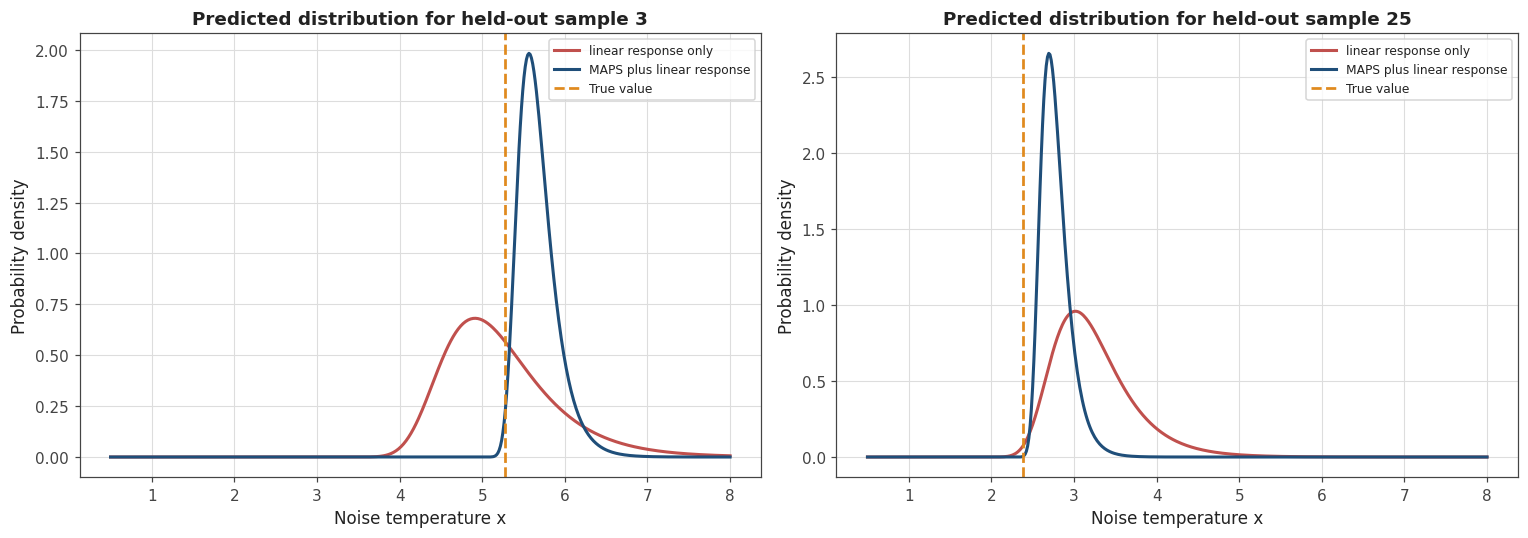

The narrower the distribution, the more confident the network is. The network that
sees the nonlinear data should give the tighter distribution, especially when the
true noise temperature is high, which is exactly the regime where a linear
measurement has stopped being informative.


In [20]:
from scipy.special import gamma as gamma_function


def train_uncertainty_network(feature_matrix, scaler_object, main_network_model,
                              true_target_values, training_sample_count, random_seed):
    """
    Training a second network that predicts how wrong the first network is likely to be.

    Computing the first network's absolute error on the training set, then fitting a small
    network to predict that error from the same inputs. Converting the predicted error into
    the scale parameter of a Gumbel distribution, using the known relationship between the
    mean absolute deviation and the scale of that distribution.
    """
    scaled_features = scaler_object.transform(feature_matrix)

    training_predictions = main_network_model.predict(scaled_features[:training_sample_count, :])
    training_absolute_errors = np.abs(
        training_predictions[:, 2] - true_target_values[:training_sample_count, 2]
    )

    uncertainty_model = MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=1e-3,
        max_iter=600,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=random_seed,
    )

    uncertainty_model.fit(scaled_features[:training_sample_count, :], training_absolute_errors)

    return uncertainty_model


def gumbel_probability_density(x_values, mode_value, scale_value):
    """
    Evaluating the Gumbel probability density used to describe the prediction uncertainty.
    """
    safe_scale = max(scale_value, 1e-6)
    standardised = (x_values - mode_value) / safe_scale
    return (1.0 / safe_scale) * np.exp(-standardised - np.exp(-standardised))


uncertainty_models_by_network = {}

for network_name, feature_matrix, hidden_layer_sizes in network_configurations:

    trained_result = trained_network_results[network_name]

    uncertainty_model = train_uncertainty_network(
        feature_matrix,
        trained_result["scaler"],
        trained_result["model"],
        target_values,
        training_sample_count,
        ANN_RANDOM_SEED + 7,
    )

    uncertainty_models_by_network[network_name] = uncertainty_model

    print("Uncertainty network trained for: " + network_name)

print()

demonstration_sample_indices = [3, 25]

figure_object, axis_array = plt.subplots(1, 2, figsize=(14, 5))

noise_temperature_axis = np.linspace(0.5, 8.0, 500)

for panel_index in range(len(demonstration_sample_indices)):

    sample_index_within_test_set = demonstration_sample_indices[panel_index]
    axis_object = axis_array[panel_index]

    true_noise_temperature = target_values[training_sample_count + sample_index_within_test_set, 2]

    for network_name, network_colour in [("linear response only", COLOUR_SECONDARY),
                                         ("MAPS plus linear response", COLOUR_PRIMARY)]:

        trained_result = trained_network_results[network_name]
        uncertainty_model = uncertainty_models_by_network[network_name]

        if network_name == "linear response only":
            this_feature_matrix = linear_only_features
        else:
            this_feature_matrix = maps_features

        scaled_features = trained_result["scaler"].transform(this_feature_matrix)
        single_row = scaled_features[training_sample_count + sample_index_within_test_set, :]
        single_row = single_row.reshape(1, -1)

        predicted_mode = trained_result["model"].predict(single_row)[0, 2]
        predicted_absolute_error = float(uncertainty_model.predict(single_row)[0])

        gumbel_scale = max(predicted_absolute_error / 1.1, 0.02)

        density_values = gumbel_probability_density(
            noise_temperature_axis, predicted_mode, gumbel_scale
        )

        axis_object.plot(noise_temperature_axis, density_values,
                         "-", color=network_colour, linewidth=2.0, label=network_name)

    axis_object.axvline(true_noise_temperature, color=COLOUR_HIGHLIGHT,
                        linestyle="--", linewidth=1.8, label="True value")
    axis_object.set_xlabel("Noise temperature x")
    axis_object.set_ylabel("Probability density")
    axis_object.set_title("Predicted distribution for held-out sample "
                          + str(sample_index_within_test_set))
    axis_object.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("The narrower the distribution, the more confident the network is. The network that")
print("sees the nonlinear data should give the tighter distribution, especially when the")
print("true noise temperature is high, which is exactly the regime where a linear")
print("measurement has stopped being informative.")

## Cell 21: The early detection test

This is the central experiment of Part 3, and the one to be most careful about interpreting.

We simulate a material that gels slowly, by letting its noise temperature x fall steadily
through time. At each moment we generate what the instrument would measure, then ask both
networks what they think x is.

A material is judged to have changed state when x crosses a threshold. From the theory in
reference [2] the linear response only reveals a change once x drops below about three, while
the nonlinear response starts changing once x drops below about five. If that holds, the MAPS
network will raise the alarm first, and the gap between the two alarms is the lead time.

**An important caveat.** This separation between three and five is a property of the soft
glassy rheology model. Blood clotting is fibrin polymerisation, which is a different physical
process, and nobody has shown that an equivalent early-warning gap exists there. What this
cell demonstrates is that the method works and that our implementation reproduces the
published behaviour. Whether blood behaves the same way is the open question this project is
set up to answer, not something already established.

Simulating an ageing material and measuring it at 25 moments


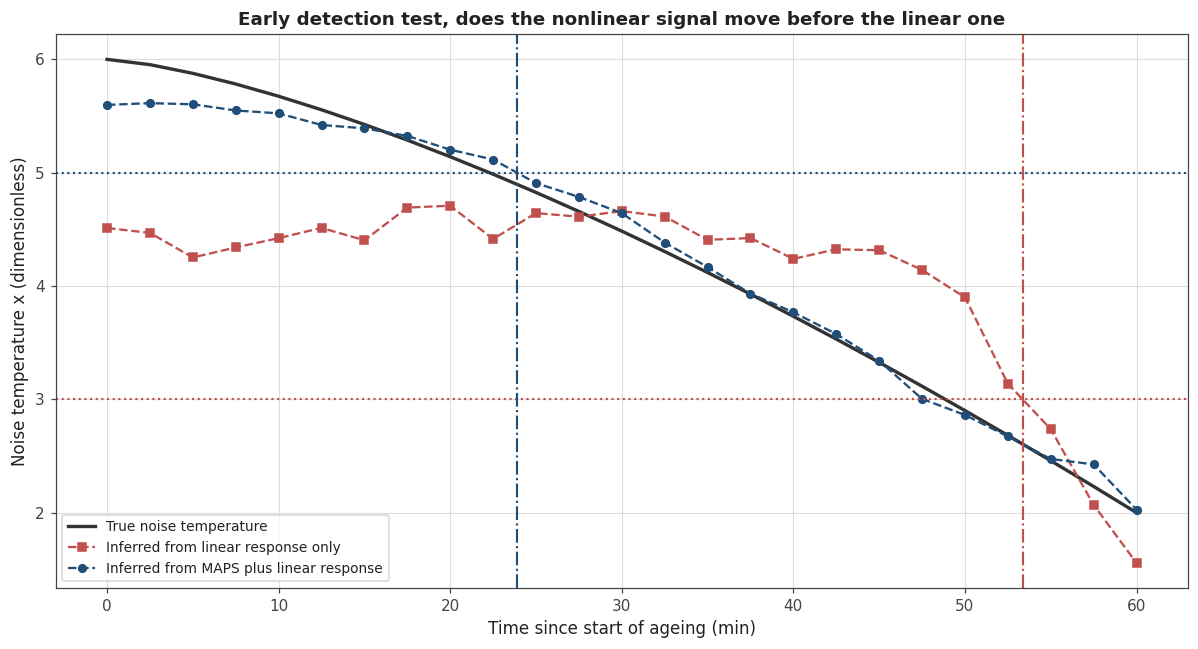

Detection times
  MAPS network raises the alarm at x = 5:   23.89 min   (true crossing 22.29 min)
  Linear network raises the alarm at x = 3: 53.36 min   (true crossing 48.85 min)

  Lead time gained by using the nonlinear data: 29.47 min
  As a fraction of the total ageing time: 49 percent

Remember what this does and does not show. It shows the pipeline reproduces the
published soft glassy behaviour correctly. It does not show that blood behaves the
same way. Testing that is what the real Haemograph coagulation data is for.


In [21]:
ageing_time_points = np.linspace(0.0, 60.0, 25)

ageing_start_noise_temperature = 6.0
ageing_end_noise_temperature = 2.0

ageing_true_noise_temperatures = (
    ageing_start_noise_temperature
    - (ageing_start_noise_temperature - ageing_end_noise_temperature)
    * (ageing_time_points / ageing_time_points[-1]) ** 1.4
)

ageing_element_stiffness = 500.0
ageing_attempt_frequency = 1000.0
ageing_tensorial_c = 3.0
ageing_tensorial_d = -0.4

ageing_random_generator = np.random.default_rng(ANN_RANDOM_SEED + 99)

ageing_linear_rows = []
ageing_third_order_rows = []

print("Simulating an ageing material and measuring it at " + str(len(ageing_time_points))
      + " moments")

for time_index in range(len(ageing_time_points)):

    current_noise_temperature = ageing_true_noise_temperatures[time_index]

    relaxation_nodes, relaxation_weights = build_relaxation_time_quadrature(
        current_noise_temperature
    )

    linear_row = []
    for single_tone in MAPS_TONE_SET:
        dimensionless_frequency = single_tone * 1.0 / ageing_attempt_frequency
        linear_row.append(ageing_element_stiffness * sgr_linear_complex_modulus(
            dimensionless_frequency, relaxation_nodes, relaxation_weights
        ))

    third_order_row = []
    for one_triplet in MAPS_FREQUENCY_TRIPLETS:

        first_frequency = one_triplet[0] * 1.0 / ageing_attempt_frequency
        second_frequency = one_triplet[1] * 1.0 / ageing_attempt_frequency
        third_frequency = one_triplet[2] * 1.0 / ageing_attempt_frequency

        scalar_part = ageing_element_stiffness * sgr_third_order_modulus(
            first_frequency, second_frequency, third_frequency,
            current_noise_temperature, relaxation_nodes, relaxation_weights
        )

        separable_part = compute_time_strain_separable_part(
            linear_row, one_triplet, ageing_element_stiffness, ageing_attempt_frequency,
            current_noise_temperature, relaxation_nodes, relaxation_weights
        )

        third_order_row.append(ageing_tensorial_c * scalar_part
                               + ageing_tensorial_d * separable_part)

    ageing_linear_rows.append(linear_row)
    ageing_third_order_rows.append(third_order_row)

ageing_linear_rows = np.array(ageing_linear_rows)
ageing_third_order_rows = np.array(ageing_third_order_rows)

ageing_linear_rows = ageing_linear_rows * (
    1.0 + measurement_noise_fraction
    * ageing_random_generator.standard_normal(ageing_linear_rows.shape)
)
ageing_third_order_rows = ageing_third_order_rows * (
    1.0 + measurement_noise_fraction
    * ageing_random_generator.standard_normal(ageing_third_order_rows.shape)
)

ageing_linear_features = build_network_features(ageing_linear_rows)
ageing_maps_features = np.concatenate([
    build_network_features(ageing_linear_rows),
    build_network_features(ageing_third_order_rows),
], axis=1)

linear_result = trained_network_results["linear response only"]
maps_result = trained_network_results["MAPS plus linear response"]

linear_inferred_noise_temperature = linear_result["model"].predict(
    linear_result["scaler"].transform(ageing_linear_features)
)[:, 2]

maps_inferred_noise_temperature = maps_result["model"].predict(
    maps_result["scaler"].transform(ageing_maps_features)
)[:, 2]

LINEAR_DETECTION_THRESHOLD = 3.0
MAPS_DETECTION_THRESHOLD = 5.0


def find_first_threshold_crossing(time_array, value_array, threshold_value):
    """
    Finding the first moment a falling curve drops below a threshold.

    Interpolating between the two surrounding points so the answer is not stuck on the
    measurement grid, and returning NaN when the curve never crosses.
    """
    for point_index in range(1, len(value_array)):

        previous_value = value_array[point_index - 1]
        current_value = value_array[point_index]

        if previous_value > threshold_value and current_value <= threshold_value:
            previous_time = time_array[point_index - 1]
            current_time = time_array[point_index]
            interpolation_weight = ((previous_value - threshold_value)
                                    / (previous_value - current_value))
            return previous_time + interpolation_weight * (current_time - previous_time)

    return np.nan


linear_alarm_time = find_first_threshold_crossing(
    ageing_time_points, linear_inferred_noise_temperature, LINEAR_DETECTION_THRESHOLD
)
maps_alarm_time = find_first_threshold_crossing(
    ageing_time_points, maps_inferred_noise_temperature, MAPS_DETECTION_THRESHOLD
)

true_linear_alarm_time = find_first_threshold_crossing(
    ageing_time_points, ageing_true_noise_temperatures, LINEAR_DETECTION_THRESHOLD
)
true_maps_alarm_time = find_first_threshold_crossing(
    ageing_time_points, ageing_true_noise_temperatures, MAPS_DETECTION_THRESHOLD
)

figure_object, axis_object = plt.subplots(figsize=(11, 6))

axis_object.plot(ageing_time_points, ageing_true_noise_temperatures,
                 "-", color="#333333", linewidth=2.2, label="True noise temperature")
axis_object.plot(ageing_time_points, linear_inferred_noise_temperature,
                 "s--", color=COLOUR_SECONDARY, markersize=5,
                 label="Inferred from linear response only")
axis_object.plot(ageing_time_points, maps_inferred_noise_temperature,
                 "o--", color=COLOUR_PRIMARY, markersize=5,
                 label="Inferred from MAPS plus linear response")

axis_object.axhline(LINEAR_DETECTION_THRESHOLD, color=COLOUR_SECONDARY,
                    linestyle=":", linewidth=1.4)
axis_object.axhline(MAPS_DETECTION_THRESHOLD, color=COLOUR_PRIMARY,
                    linestyle=":", linewidth=1.4)

if np.isfinite(maps_alarm_time):
    axis_object.axvline(maps_alarm_time, color=COLOUR_PRIMARY, linestyle="-.", linewidth=1.4)
if np.isfinite(linear_alarm_time):
    axis_object.axvline(linear_alarm_time, color=COLOUR_SECONDARY,
                        linestyle="-.", linewidth=1.4)

axis_object.set_xlabel("Time since start of ageing (min)")
axis_object.set_ylabel("Noise temperature x (dimensionless)")
axis_object.set_title("Early detection test, does the nonlinear signal move before the linear one")
axis_object.legend(fontsize=9)

plt.tight_layout()
plt.show()

print("Detection times")
print("  MAPS network raises the alarm at x = 5:   "
      + ("%.2f" % maps_alarm_time) + " min   (true crossing "
      + ("%.2f" % true_maps_alarm_time) + " min)")
print("  Linear network raises the alarm at x = 3: "
      + ("%.2f" % linear_alarm_time) + " min   (true crossing "
      + ("%.2f" % true_linear_alarm_time) + " min)")
print()

if np.isfinite(maps_alarm_time) and np.isfinite(linear_alarm_time):
    lead_time_minutes = linear_alarm_time - maps_alarm_time
    print("  Lead time gained by using the nonlinear data: "
          + ("%.2f" % lead_time_minutes) + " min")
    print("  As a fraction of the total ageing time: "
          + ("%.0f" % (100.0 * lead_time_minutes / ageing_time_points[-1])) + " percent")

print()
print("Remember what this does and does not show. It shows the pipeline reproduces the")
print("published soft glassy behaviour correctly. It does not show that blood behaves the")
print("same way. Testing that is what the real Haemograph coagulation data is for.")

# Part 4: The blood model from the Armstrong paper

## Cell 22: The thixotropic elasto-visco-plastic equations

Everything so far has been about gelation. Blood also does something else that matters, which
is the reason Haemograph's instrument sees the signals it does.

Red blood cells stack into loose columns called rouleaux. Shearing the blood breaks those
stacks apart, and letting it rest lets them rebuild. That build up and break down is
thixotropy, and it happens on its own timescale, separate from any clotting.

Reference [1] captures this with a structure parameter called lambda, which runs from one, a
fully built structure, down to zero, completely broken. This cell implements the two coupled
equations from that paper: one for how the stress evolves and one for how lambda evolves.

This matters for the gel point work because thixotropic breakdown and clot formation both
change the measured moduli. Anything that claims to detect a clot needs to be able to tell
those two apart.

In [22]:
from scipy.integrate import solve_ivp

ARMSTRONG_DONOR_THREE_PARAMETERS = {
    "yield_stress_pascal": 0.0034,
    "infinite_shear_viscosity": 0.0028,
    "structural_viscosity": 0.019,
    "elastic_modulus_pascal": 0.29,
    "breakdown_time_ratio": 0.77,
    "buildup_time_ratio": 0.34,
    "structure_rate_constant": 0.88,
}


def compute_steady_state_structure(shear_rate_value, breakdown_time_ratio,
                                   buildup_time_ratio):
    """
    Computing the structure level a blood sample settles at when held at a constant shear rate.

    This is the steady state of the structure evolution equation, found by setting the rate
    of change of lambda to zero. Using it to start the simulation from a physically sensible
    state rather than an arbitrary one.
    """
    absolute_shear_rate = abs(float(shear_rate_value))

    numerator = buildup_time_ratio * np.sqrt(absolute_shear_rate) + 1.0
    denominator = (breakdown_time_ratio * absolute_shear_rate
                   + buildup_time_ratio * np.sqrt(absolute_shear_rate) + 1.0)

    return numerator / denominator


def simulate_blood_step_experiment(initial_shear_rate, final_shear_rate, model_parameters,
                                   total_duration_seconds, output_point_count=1500):
    """
    Simulating a sudden step in shear rate applied to blood, using the model of reference [1].

    Solving the two coupled ordinary differential equations together, one for the total
    stress and one for the structure parameter lambda. Starting from the steady state that
    matches the initial shear rate, then holding the final shear rate for the whole run.

    Returning the time array, the stress history and the structure history.
    """
    yield_stress = model_parameters["yield_stress_pascal"]
    infinite_viscosity = model_parameters["infinite_shear_viscosity"]
    structural_viscosity = model_parameters["structural_viscosity"]
    elastic_modulus = model_parameters["elastic_modulus_pascal"]
    breakdown_ratio = model_parameters["breakdown_time_ratio"]
    buildup_ratio = model_parameters["buildup_time_ratio"]
    structure_rate = model_parameters["structure_rate_constant"]

    def evolution_equations(current_time, state_vector):
        """
        Evaluating the rate of change of stress and structure at one instant.
        """
        current_stress = state_vector[0]
        current_structure = np.clip(state_vector[1], 1e-6, 1.0)

        total_viscosity = current_structure * structural_viscosity + infinite_viscosity
        absolute_stress = max(abs(current_stress), 1e-12)

        plastic_factor = max(
            0.0,
            (absolute_stress - current_structure * yield_stress)
            / (total_viscosity * absolute_stress),
        )

        stress_rate = elastic_modulus * (final_shear_rate - plastic_factor * current_stress)

        plastic_shear_rate = abs(plastic_factor * current_stress)

        structure_rate_of_change = structure_rate * (
            -breakdown_ratio * plastic_shear_rate * current_structure
            + buildup_ratio * np.sqrt(plastic_shear_rate) * (1.0 - current_structure)
            + (1.0 - current_structure)
        )

        return [stress_rate, structure_rate_of_change]

    initial_structure = compute_steady_state_structure(
        initial_shear_rate, breakdown_ratio, buildup_ratio
    )
    initial_stress = (initial_structure * yield_stress
                      + (initial_structure * structural_viscosity + infinite_viscosity)
                      * initial_shear_rate)

    output_time_array = np.linspace(0.0, total_duration_seconds, output_point_count)

    solution_object = solve_ivp(
        evolution_equations,
        [0.0, total_duration_seconds],
        [initial_stress, initial_structure],
        t_eval=output_time_array,
        method="BDF",
        rtol=1e-7,
        atol=1e-11,
    )

    return solution_object.t, solution_object.y[0], solution_object.y[1]


example_time, example_stress, example_structure = simulate_blood_step_experiment(
    0.25, 5.0, ARMSTRONG_DONOR_THREE_PARAMETERS, 40.0
)

print("Blood step simulation completed")
print("  initial shear rate: 0.25 per second")
print("  final shear rate:   5.0 per second")
print("  starting structure: " + ("%.4f" % example_structure[0]))
print("  final structure:    " + ("%.4f" % example_structure[-1]))
print("  peak stress:        " + ("%.5f" % np.max(example_stress)) + " Pa")

Blood step simulation completed
  initial shear rate: 0.25 per second
  final shear rate:   5.0 per second
  starting structure: 0.8587
  final structure:    0.3138
  peak stress:        0.07884 Pa


## Cell 23: Step up and step down in shear rate

Here we run several step experiments and plot both the stress and the hidden structure
parameter.

The feature to look for in the step up panel is the overshoot. The stress briefly rises above
where it eventually settles. That happens because the rouleaux structure has not broken down
yet when the shear rate suddenly increases, so the blood is momentarily stiffer than it will
be a moment later.

Simpler models without a thixotropic term cannot reproduce that overshoot at all, which is
the main argument reference [1] makes for including one.

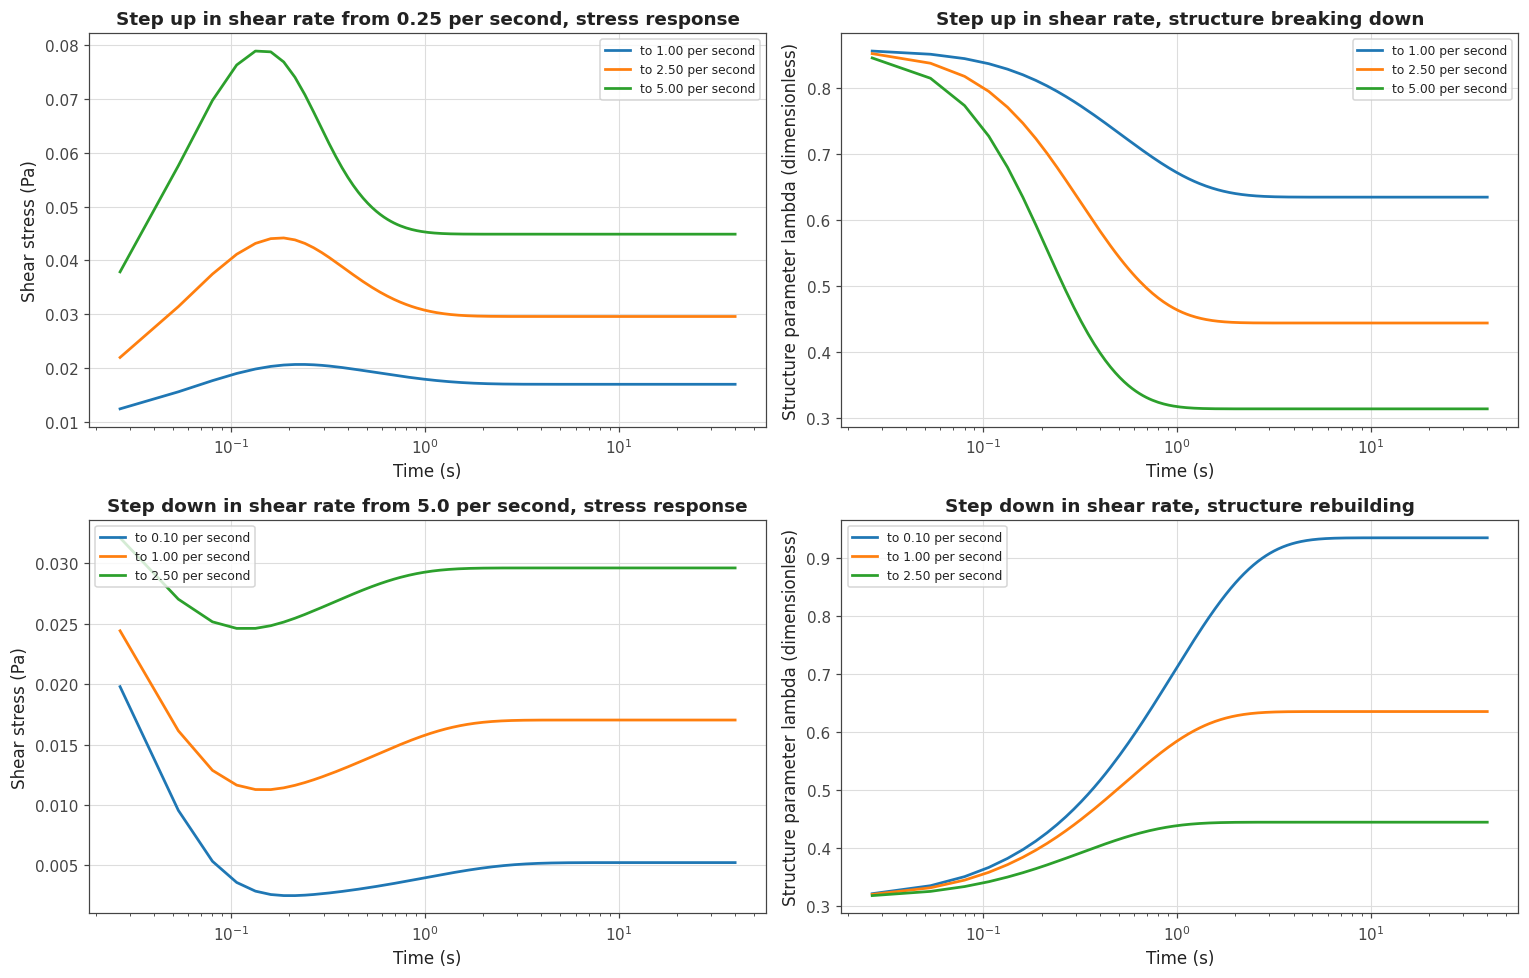

The structure panels on the right are the point of the model. They are showing
something no instrument measures directly, the amount of rouleaux structure present
at each instant, inferred from the stress the instrument does measure.


In [23]:
step_up_final_rates = [1.0, 2.5, 5.0]
step_down_final_rates = [0.1, 1.0, 2.5]

figure_object, axis_array = plt.subplots(2, 2, figsize=(14, 9))

for final_rate in step_up_final_rates:

    step_time, step_stress, step_structure = simulate_blood_step_experiment(
        0.25, final_rate, ARMSTRONG_DONOR_THREE_PARAMETERS, 40.0
    )

    axis_array[0][0].semilogx(step_time[1:], step_stress[1:], "-", linewidth=1.8,
                              label=("to %.2f per second" % final_rate))
    axis_array[0][1].semilogx(step_time[1:], step_structure[1:], "-", linewidth=1.8,
                              label=("to %.2f per second" % final_rate))

for final_rate in step_down_final_rates:

    step_time, step_stress, step_structure = simulate_blood_step_experiment(
        5.0, final_rate, ARMSTRONG_DONOR_THREE_PARAMETERS, 40.0
    )

    axis_array[1][0].semilogx(step_time[1:], step_stress[1:], "-", linewidth=1.8,
                              label=("to %.2f per second" % final_rate))
    axis_array[1][1].semilogx(step_time[1:], step_structure[1:], "-", linewidth=1.8,
                              label=("to %.2f per second" % final_rate))

axis_array[0][0].set_xlabel("Time (s)")
axis_array[0][0].set_ylabel("Shear stress (Pa)")
axis_array[0][0].set_title("Step up in shear rate from 0.25 per second, stress response")
axis_array[0][0].legend(fontsize=8)

axis_array[0][1].set_xlabel("Time (s)")
axis_array[0][1].set_ylabel("Structure parameter lambda (dimensionless)")
axis_array[0][1].set_title("Step up in shear rate, structure breaking down")
axis_array[0][1].legend(fontsize=8)

axis_array[1][0].set_xlabel("Time (s)")
axis_array[1][0].set_ylabel("Shear stress (Pa)")
axis_array[1][0].set_title("Step down in shear rate from 5.0 per second, stress response")
axis_array[1][0].legend(fontsize=8)

axis_array[1][1].set_xlabel("Time (s)")
axis_array[1][1].set_ylabel("Structure parameter lambda (dimensionless)")
axis_array[1][1].set_title("Step down in shear rate, structure rebuilding")
axis_array[1][1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("The structure panels on the right are the point of the model. They are showing")
print("something no instrument measures directly, the amount of rouleaux structure present")
print("at each instant, inferred from the stress the instrument does measure.")

# Part 5: Summary and next steps

## Cell 24: What was built, what it shows, and what is still missing

This final cell states plainly what the notebook establishes and, just as importantly, what it
does not. Being clear about the second part is what keeps the project honest when the results
are written up.

In [24]:
print("WHAT WAS BUILT")
print()
print("  Part 1. A chirp processing pipeline that turns raw rheometer stress and strain")
print("          time series into viscoelastic spectra, applied to a real recording of a")
print("          material that stiffened by four orders of magnitude while being measured.")
print()
print("  Part 2. A synthetic gelling material built from fractional viscoelastic models,")
print("          with a gel time chosen by us, plus two gel point detectors scored against")
print("          that known answer across a range of measurement noise levels.")
print()
print("  Part 3. The soft glassy rheology model, its linear response and its weakly")
print("          nonlinear MAPS response, implemented from the integral definitions and")
print("          validated against published values. Two neural networks trained to read")
print("          the material state out of that response, with uncertainty estimates, and")
print("          an early detection experiment comparing them.")
print()
print("  Part 4. The thixotropic elasto-visco-plastic blood model, which describes rouleaux")
print("          breakdown and rebuilding, the other process that changes blood moduli.")
print()

print("WHAT THE RESULTS SHOW")
print()
print("  The Winter and Chambon detector, which looks for the moment tan delta agrees across")
print("  frequencies, gives one unambiguous gel time. The single frequency crossover gives a")
print("  different answer depending on which frequency is chosen, so it should be treated as")
print("  a baseline to beat rather than as ground truth.")
print()
print("  Our MAPS implementation reproduces the published soft glassy values, so the network")
print("  results rest on correct physics rather than on a coincidence of fitting.")
print()
print("  Adding the nineteen nonlinear measurements lets the network track the material state")
print("  well past the point where the linear response alone has stopped being informative,")
print("  and it raises the alarm earlier in the simulated ageing experiment.")
print()

print("WHAT IS STILL MISSING")
print()
print("  No blood coagulation data. Every blood dataset available so far is anticoagulated,")
print("  so it contains no gel point at all. The gel point work is currently demonstrated on")
print("  synthetic data and on one industrial curing sample.")
print()
print("  No reference gel time. Without an independently measured clot time for each run, an")
print("  estimate can be produced but its accuracy cannot be quantified.")
print()
print("  No real MAPS data. A three-tone waveform has never been run on blood. The network")
print("  results in Part 3 are trained and tested entirely on synthetic soft glassy data.")
print()
print("  No evidence yet that blood shows the early warning gap. The separation between the")
print("  linear and nonlinear detection thresholds is a property of the soft glassy model.")
print("  Blood clotting is fibrin polymerisation, which is a different process. Whether the")
print("  same gap exists there is the open question, not an established result.")
print()

print("WHAT TO ASK HAEMOGRAPH FOR")
print()
print("  1. Can the rheometer accept an arbitrary user-defined waveform, and export the raw")
print("     stress and strain time series rather than only the reduced moduli. The chirp file")
print("     used in Part 1 proves an ARES G2 can do both. If Haemograph's instrument can too,")
print("     the chirp method and the three-tone MAPS method are both feasible.")
print()
print("  2. Time-resolved coagulation runs, with the oscillation frequency, sampling rate and")
print("     total duration recorded.")
print()
print("  3. An independent reference clot time for each run, from the instrument itself or")
print("     from a comparator device. This is the single most important item, because without")
print("     it accuracy cannot be measured.")
print()
print("  4. An amplitude sweep at a fixed moment during clotting, to find the largest")
print("     amplitude that does not disturb the forming clot. Reference [2] had to discard")
print("     half its nonlinear data over exactly this problem on a more robust material.")
print()

print("NEXT STEPS IN THE CODE")
print()
print("  Replace the soft glassy model in Part 3 with the fractional Maxwell family used in")
print("  Part 2, so the gel point is defined inside the model rather than as a threshold on a")
print("  soft glassy parameter, and retrain the networks on that.")
print()
print("  Add the Gaussian process superposition method of reference [7] to combine the")
print("  spectral snapshots into a single master curve, which should sharpen the gel time")
print("  estimate and give it a proper confidence interval.")
print()
print("  Use the wavelet machinery from Part 1 to extract the MAPS response without assuming")
print("  the material holds still during the measurement window. That assumption gets worse")
print("  the closer the material is to the gel point, which is exactly where it matters most.")

WHAT WAS BUILT

  Part 1. A chirp processing pipeline that turns raw rheometer stress and strain
          time series into viscoelastic spectra, applied to a real recording of a
          material that stiffened by four orders of magnitude while being measured.

  Part 2. A synthetic gelling material built from fractional viscoelastic models,
          with a gel time chosen by us, plus two gel point detectors scored against
          that known answer across a range of measurement noise levels.

  Part 3. The soft glassy rheology model, its linear response and its weakly
          nonlinear MAPS response, implemented from the integral definitions and
          validated against published values. Two neural networks trained to read
          the material state out of that response, with uncertainty estimates, and
          an early detection experiment comparing them.

  Part 4. The thixotropic elasto-visco-plastic blood model, which describes rouleaux
          breakdown and rebuildi